<div dir="rtl" style="text-align: right;">
<h2 style="background:#5d6d7e; color:white; padding:8px 14px; border-radius:8px;">1. کتابخانه‌ها و تنظیمات</h2>
</div>

In [1]:
import os
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from dotenv import load_dotenv
from scipy import stats
from sqlalchemy import URL, create_engine, text, bindparam
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.api as sm

pio.templates.default = 'plotly_dark'
pio.renderers.default = 'notebook'
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:.3f}'.format)

current_dir = Path.cwd().resolve()

ROOT = next(
    (
        path
        for path in [current_dir, *current_dir.parents]
        if (path / "notebooks" / "nba_analysis.ipynb").is_file()
    ),
    None,
)

if ROOT is None:
    raise FileNotFoundError(
        "Project root was not found. Run the notebook from within the repository."
    )

notebooks_dir = str(ROOT / "notebooks")

if notebooks_dir not in sys.path:
    sys.path.insert(0, notebooks_dir)

import nba_top_players
from partially_overlapping_tests import partially_overlapping_t

load_dotenv(ROOT / ".env")

DB_PATH = ROOT / "database" / "data" / "nba_star.db"

if not DB_PATH.is_file():
    raise FileNotFoundError(f"Database file was not found: {DB_PATH}")

<div dir="rtl" style="text-align: right;">
<h2 style="background:#2e86c1; color:white; padding:8px 14px; border-radius:8px;">2. خواندن داده‌ها</h2>
</div>

In [2]:
engine = create_engine(
    URL.create("sqlite", database=str(DB_PATH))
)

with engine.connect() as connection:
    integrity_result = connection.execute(
        text("PRAGMA integrity_check")
    ).scalars().all()

    table_names = connection.execute(
        text(
            "SELECT name FROM sqlite_master "
            "WHERE type = 'table' ORDER BY name"
        )
    ).scalars().all()

if integrity_result != ["ok"]:
    raise RuntimeError(f"Database integrity check failed: {integrity_result}")

required_tables = {
    "fact_player_stats",
    "dim_player",
    "dim_season",
    "dim_team_scope",
    "dim_player_context",
    "dim_phase",
}

missing_tables = required_tables - set(table_names)

if missing_tables:
    raise RuntimeError(f"Required tables are missing: {sorted(missing_tables)}")

print(f"Database: {DB_PATH}")
print("Integrity check: OK")
print(f"Tables: {len(table_names)}")

Database: C:\Users\vortex\nba_build\Group1\database\data\nba_star.db
Integrity check: OK
Tables: 9


<div dir="rtl" style="text-align: right;">
<h2 style="background:#17a589; color:white; padding:8px 14px; border-radius:8px;">3. پاک‌سازی داده‌ها</h2>
<h3 style="color:#17a589; border-right:5px solid #17a589; padding-right:10px;">3.1 داده‌های خالی</h3>
</div>

In [3]:
df_dim_player = pd.read_sql('SELECT * from dim_player',engine)
print(df_dim_player.info())

<class 'pandas.DataFrame'>
RangeIndex: 964 entries, 0 to 963
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   player_key            964 non-null    int64
 1   source_player_id      964 non-null    int64
 2   player_name           964 non-null    str  
 3   birth_date            964 non-null    str  
 4   listed_height_inches  964 non-null    int64
 5   listed_weight_pounds  964 non-null    int64
dtypes: int64(4), str(2)
memory usage: 45.3 KB
None


In [4]:
df_dim_player_context = pd.read_sql('SELECT * from dim_player_context',engine)
print(df_dim_player_context.info())

<class 'pandas.DataFrame'>
RangeIndex: 538 entries, 0 to 537
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   context_key       538 non-null    int64
 1   reported_age      538 non-null    int64
 2   experience_years  538 non-null    int64
 3   position_code     538 non-null    str  
dtypes: int64(3), str(1)
memory usage: 16.9 KB
None


In [5]:
df_dim_team_scope = pd.read_sql('SELECT * from dim_team_scope',engine)
print(df_dim_team_scope.info())

<class 'pandas.DataFrame'>
RangeIndex: 33 entries, 0 to 32
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   scope_key             33 non-null     int64  
 1   scope_code            33 non-null     str    
 2   scope_kind            33 non-null     str    
 3   source_team_id        30 non-null     float64
 4   team_name             30 non-null     str    
 5   aggregate_team_count  3 non-null      float64
dtypes: float64(2), int64(1), str(3)
memory usage: 1.7 KB
None


In [6]:
df_fact_mvp_voting = pd.read_sql('SELECT * from fact_mvp_voting',engine)
print(df_fact_mvp_voting.info())

<class 'pandas.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   mvp_vote_key                   61 non-null     int64
 1   player_key                     61 non-null     int64
 2   season_key                     61 non-null     int64
 3   scope_key                      61 non-null     int64
 4   phase_key                      61 non-null     int64
 5   context_key                    61 non-null     int64
 6   source_representative_stat_id  61 non-null     int64
 7   first_place_votes              61 non-null     int64
 8   voting_points_won              61 non-null     int64
dtypes: int64(9)
memory usage: 4.4 KB
None


In [7]:
df_fact_player_salary = pd.read_sql('SELECT * from fact_player_salary',engine)
print(df_fact_player_salary.info())

<class 'pandas.DataFrame'>
RangeIndex: 2614 entries, 0 to 2613
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   salary_key         2614 non-null   int64
 1   player_key         2614 non-null   int64
 2   season_key         2614 non-null   int64
 3   annual_salary_usd  2614 non-null   int64
dtypes: int64(4)
memory usage: 81.8 KB
None


In [8]:
df_fact_player_stats = pd.read_sql('SELECT * from fact_player_stats',engine)
print(df_fact_player_stats.info())
df_fact_player_stats = df_fact_player_stats.dropna()

<class 'pandas.DataFrame'>
RangeIndex: 4686 entries, 0 to 4685
Data columns (total 48 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   stat_key                       4686 non-null   int64  
 1   source_stat_id                 4686 non-null   int64  
 2   player_key                     4686 non-null   int64  
 3   season_key                     4686 non-null   int64  
 4   scope_key                      4686 non-null   int64  
 5   phase_key                      4686 non-null   int64  
 6   context_key                    4686 non-null   int64  
 7   totals_source_rank             4686 non-null   int64  
 8   advanced_source_rank           4686 non-null   int64  
 9   is_player_phase_total          4686 non-null   int64  
 10  awards_source_text             4686 non-null   str    
 11  games_played                   4686 non-null   int64  
 12  games_started                  4686 non-null   int64  
 13 

In [9]:
df_fact_roster = pd.read_sql('SELECT * from fact_roster',engine)
print(df_fact_roster.info())

<class 'pandas.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   roster_key   3203 non-null   int64
 1   player_key   3203 non-null   int64
 2   season_key   3203 non-null   int64
 3   scope_key    3203 non-null   int64
 4   context_key  3203 non-null   int64
dtypes: int64(5)
memory usage: 125.2 KB
None


<div dir="rtl" style="text-align: right;">
<h3 style="color:#17a589; border-right:5px solid #17a589; padding-right:10px;">3.2 داده‌های پرت</h3>
</div>

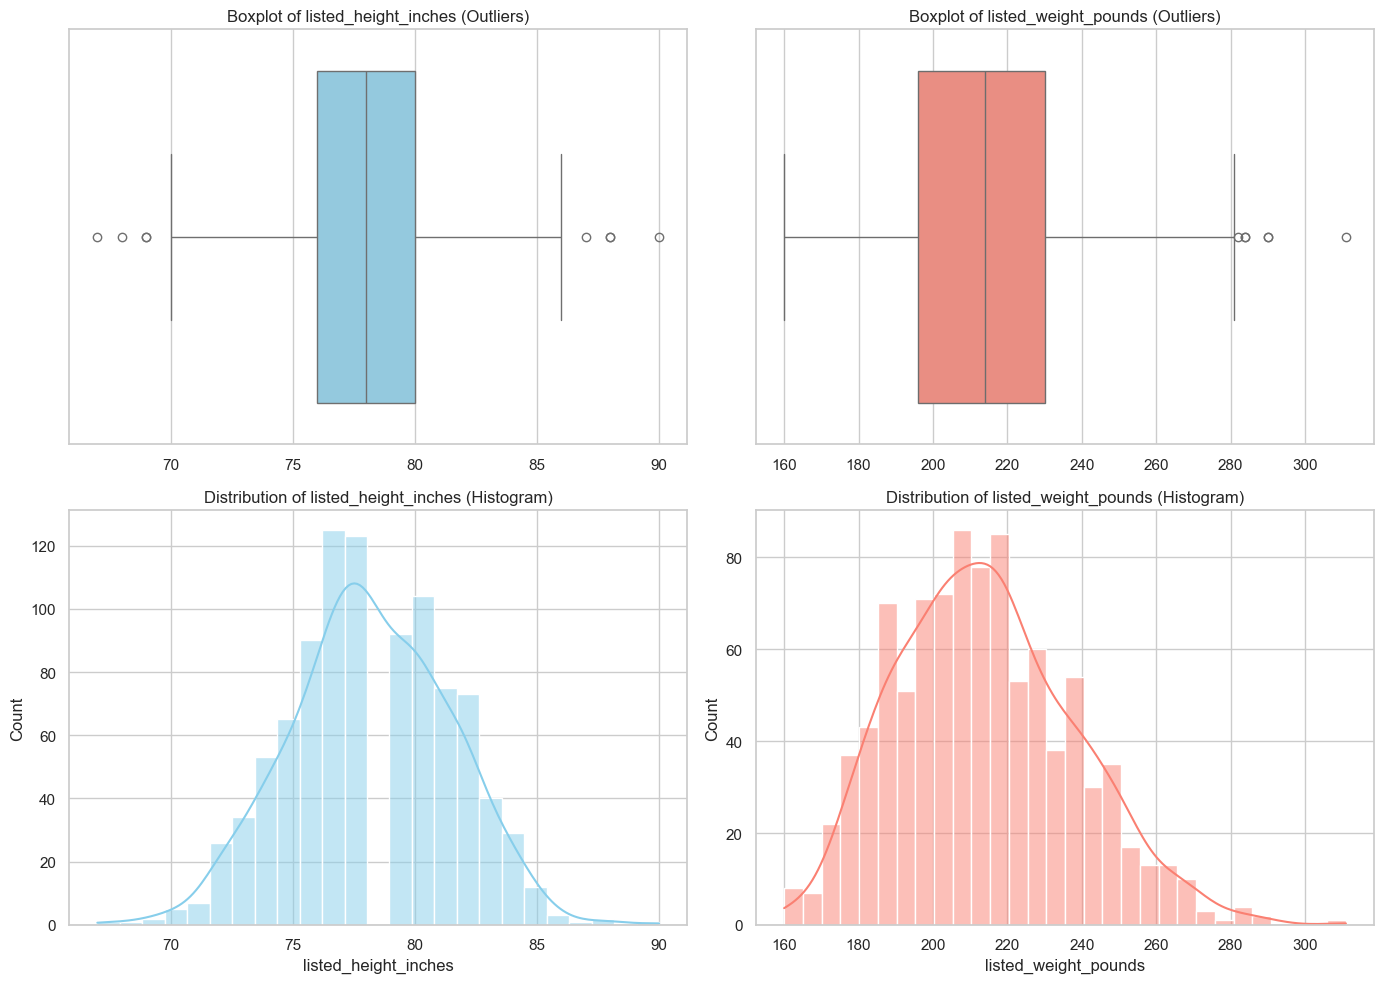

In [10]:
# ================================
# df_dim_plyer outliers
# ================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ----- listed_height_inches-----
# 1.Box Plot
sns.boxplot(x=df_dim_player['listed_height_inches'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Boxplot of listed_height_inches (Outliers)')
axes[0, 0].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_dim_player['listed_height_inches'], kde=True, ax=axes[1, 0], color='skyblue', bins=25)
axes[1, 0].set_title('Distribution of listed_height_inches (Histogram)')

# -----listed_weight_pounds-----
# 1.Box Plot
sns.boxplot(x=df_dim_player['listed_weight_pounds'], ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Boxplot of listed_weight_pounds (Outliers)')
axes[0, 1].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_dim_player['listed_weight_pounds'], kde=True, ax=axes[1, 1], color='salmon', bins=30)
axes[1, 1].set_title('Distribution of listed_weight_pounds (Histogram)')

plt.tight_layout()
plt.show()

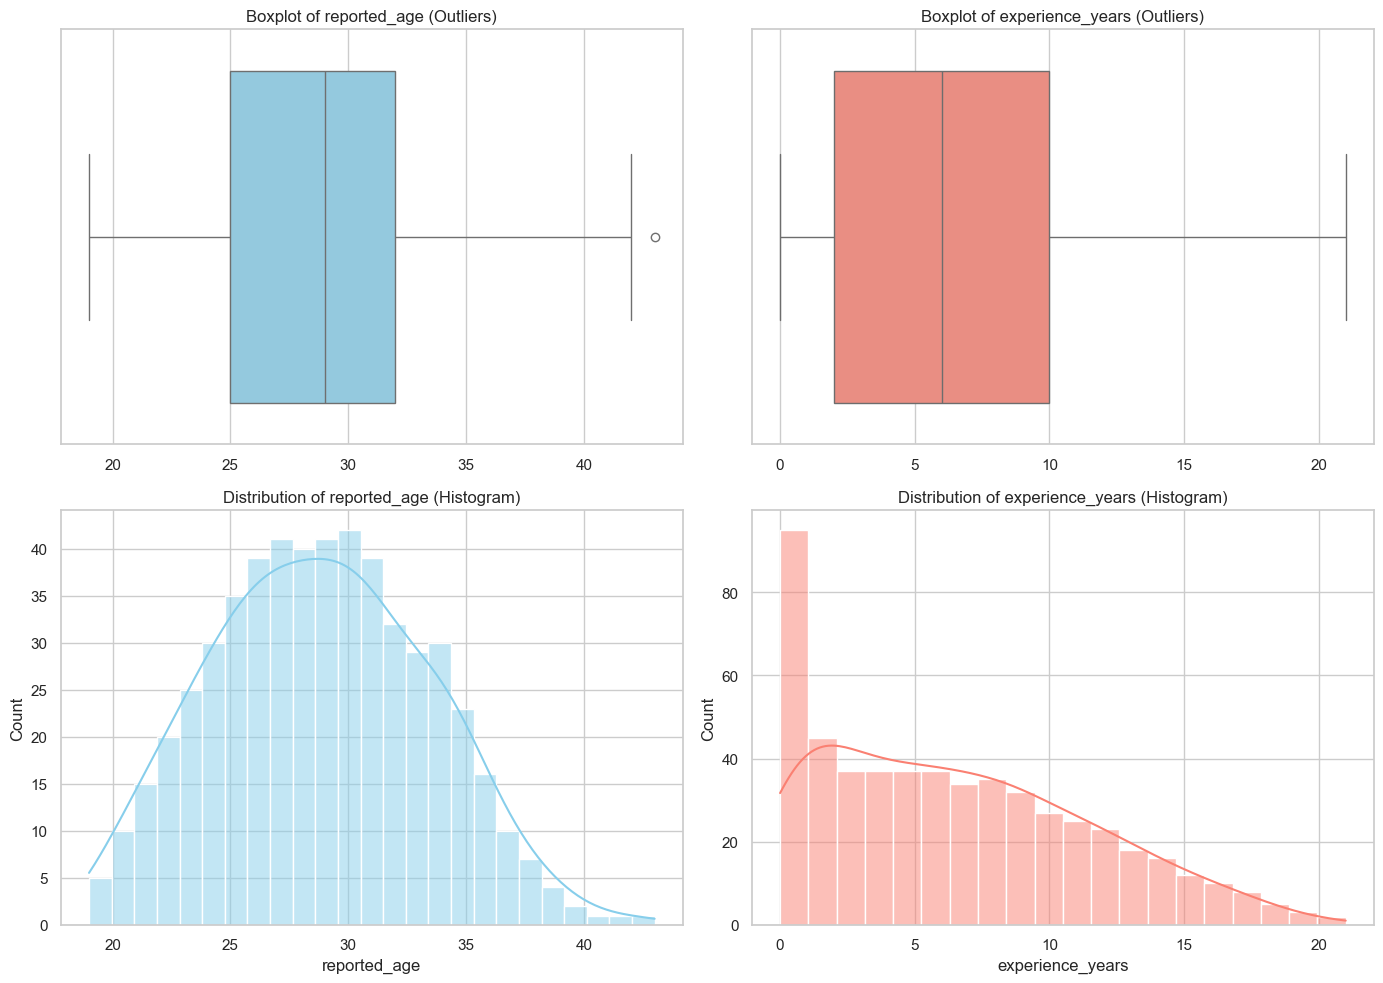

In [11]:
# ================================
# df_dim_plyer_context outliers
# ================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ----- reported_age-----
# 1.Box Plot
sns.boxplot(x=df_dim_player_context['reported_age'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Boxplot of reported_age (Outliers)')
axes[0, 0].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_dim_player_context['reported_age'], kde=True, ax=axes[1, 0], color='skyblue', bins=25)
axes[1, 0].set_title('Distribution of reported_age (Histogram)')

# -----experience_years-----
# 1.Box Plot
sns.boxplot(x=df_dim_player_context['experience_years'], ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Boxplot of experience_years (Outliers)')
axes[0, 1].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_dim_player_context['experience_years'], kde=True, ax=axes[1, 1], color='salmon', bins=20)
axes[1, 1].set_title('Distribution of experience_years (Histogram)')

plt.tight_layout()
plt.show()

Text(0.5, 1.0, 'Distribution of annual_salary_usd (Histogram)')

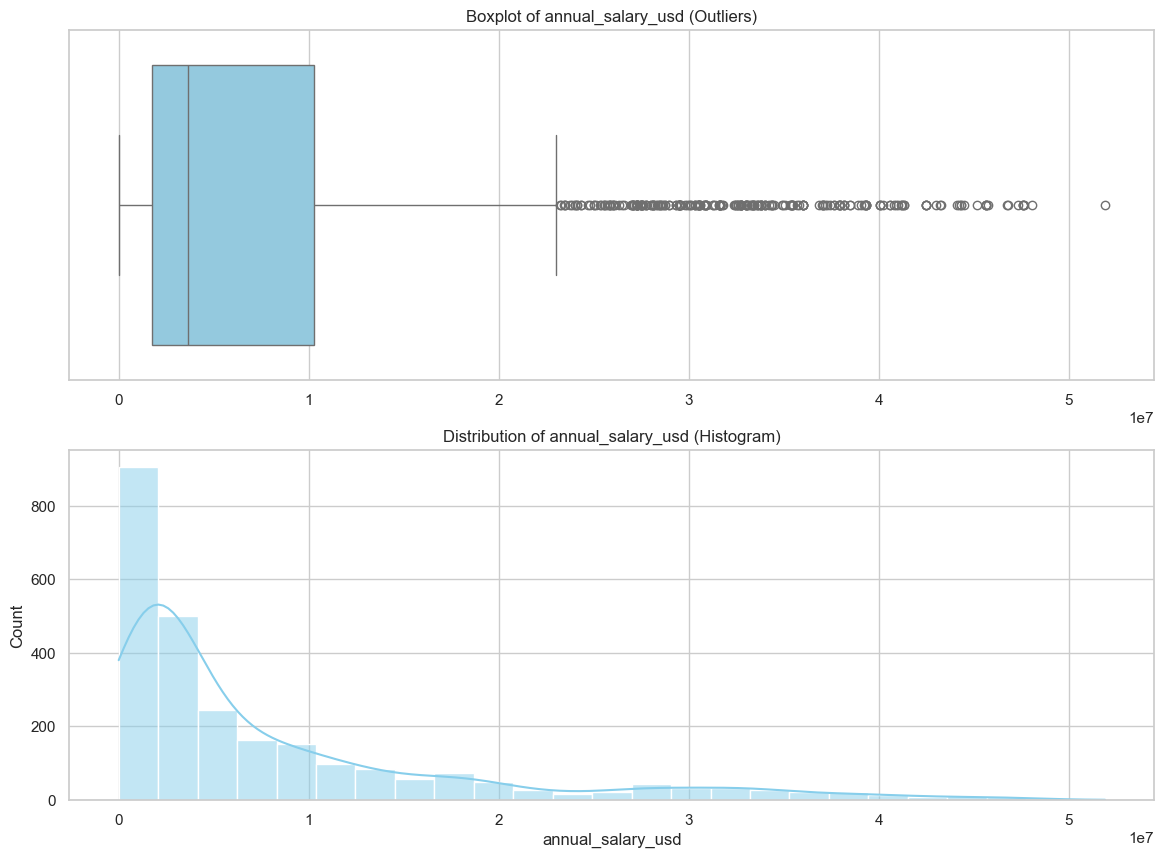

In [12]:
# ================================
# df_dim_plyer_salary outliers
# ================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, figsize=(14, 10))

# ----- annual_salary_usd-----
# 1.Box Plot
sns.boxplot(x=df_fact_player_salary['annual_salary_usd'], ax=axes[0], color='skyblue')
axes[0].set_title('Boxplot of annual_salary_usd (Outliers)')
axes[0].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_fact_player_salary['annual_salary_usd'], kde=True, ax=axes[1], color='skyblue', bins=25)
axes[1].set_title('Distribution of annual_salary_usd (Histogram)')



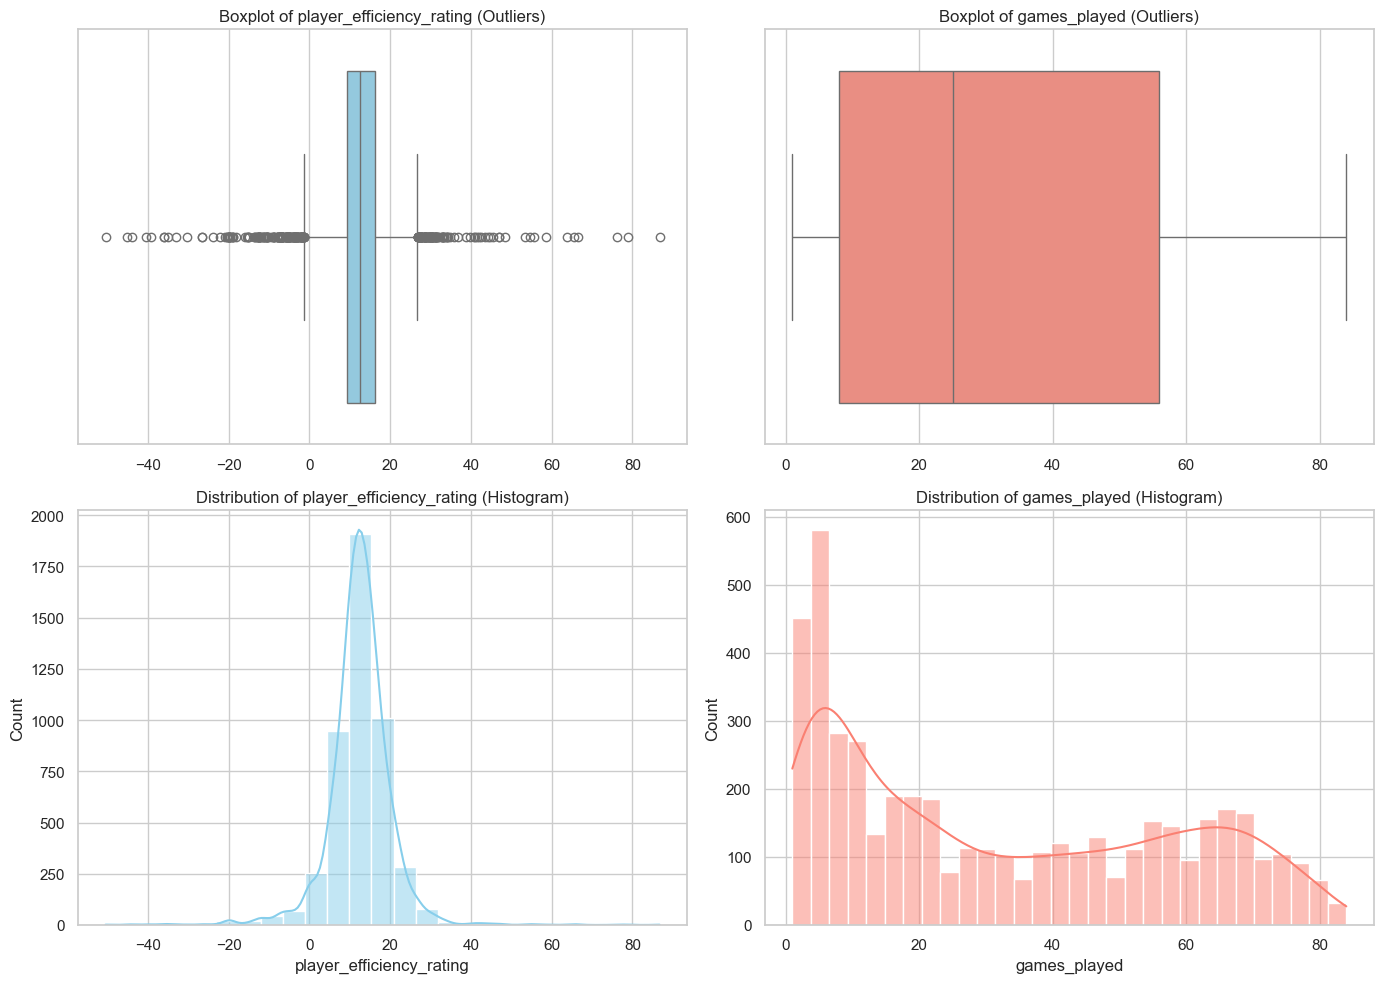

In [13]:
# ================================
# df_fact_player_stats outliers
# ================================

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ----- player_efficiency_rating-----
# 1.Box Plot
sns.boxplot(x=df_fact_player_stats['player_efficiency_rating'], ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Boxplot of player_efficiency_rating (Outliers)')
axes[0, 0].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_fact_player_stats['player_efficiency_rating'],kde=True, ax=axes[1, 0],color='skyblue',bins=25)
axes[1, 0].set_title('Distribution of player_efficiency_rating (Histogram)')

# -----games_played-----
# 1.Box Plot
sns.boxplot(x=df_fact_player_stats['games_played'], ax=axes[0, 1], color='salmon')
axes[0, 1].set_title('Boxplot of games_played (Outliers)')
axes[0, 1].set(xlabel='')

# 2.Hist Plot
sns.histplot(df_fact_player_stats['games_played'], kde=True, ax=axes[1, 1], color='salmon', bins=30)
axes[1, 1].set_title('Distribution of games_played (Histogram)')

plt.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
<h2 style="background:#28b463; color:white; padding:8px 14px; border-radius:8px;">4. شناخت داده‌ها</h2>
<h3 style="color:#28b463; border-right:5px solid #28b463; padding-right:10px;">4.1 ویژگی‌های بدنی</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h4>بارگذاری و آماده‌سازی داده‌ها</h4>
</div>

In [14]:
SEASON_LIST = ['2019-20', '2020-21', '2021-22', '2022-23', '2023-24']

body_query = """
SELECT
    p.player_key,
    p.player_name,
    s.season_label AS season,
    c.position_code AS position,
    c.reported_age AS age,
    c.experience_years AS experience,
    p.listed_height_inches,
    p.listed_weight_pounds,
    f.games_played,
    f.minutes_played,
    f.points,
    f.total_rebounds,
    f.assists,
    f.steals,
    f.blocks,
    f.field_goal_attempts,
    f.free_throw_attempts,
    f.player_efficiency_rating,
    f.usage_percentage,
    f.win_shares,
    f.win_shares_per_48_minutes,
    f.box_plus_minus,
    f.value_over_replacement_player
FROM fact_player_stats AS f
JOIN dim_player AS p ON p.player_key = f.player_key
JOIN dim_season AS s ON s.season_key = f.season_key
JOIN dim_player_context AS c ON c.context_key = f.context_key
WHERE f.phase_key = 1
  AND f.is_player_phase_total = 1
"""

with engine.connect() as connection:
    body_df = pd.read_sql_query(text(body_query), connection)

body_df['height_cm'] = body_df['listed_height_inches'] * 2.54
body_df['weight_kg'] = body_df['listed_weight_pounds'] * 0.4536
body_df['bmi'] = body_df['weight_kg'] / (body_df['height_cm'] / 100) ** 2
print(body_df.shape, '| nulls in body columns:', body_df[['height_cm', 'weight_kg', 'age', 'experience']].isna().sum().sum())
body_df.head()

(2785, 26) | nulls in body columns: 0


,player_key,player_name,season,position,age,experience,listed_height_inches,listed_weight_pounds,games_played,minutes_played,points,total_rebounds,assists,steals,blocks,field_goal_attempts,free_throw_attempts,player_efficiency_rating,usage_percentage,win_shares,win_shares_per_48_minutes,box_plus_minus,value_over_replacement_player,height_cm,weight_kg,bmi
0,1,A.J. Green,2022-23,SG,23,0,76,190,35,345,154,45,22,6,0,125,4,11.500,16.600,0.800,0.111,-0.900,0.100,193.040,86.184,23.128
1,1,A.J. Green,2023-24,SG,24,1,76,190,56,614,252,64,30,9,4,196,19,10.500,15.200,1.100,0.084,-2.100,0.000,193.040,86.184,23.128
2,2,A.J. Lawson,2022-23,SG,22,0,78,179,15,108,56,21,2,2,0,44,8,13.900,21.100,0.100,0.063,-4.400,-0.100,198.120,81.194,20.686
3,2,A.J. Lawson,2023-24,SG,23,1,78,179,42,311,136,50,20,10,3,121,23,11.200,20.000,0.200,0.036,-4.600,-0.200,198.120,81.194,20.686
4,3,AJ Griffin,2022-23,SF,19,0,78,220,72,1401,639,153,73,42,12,533,47,12.600,17.900,2.200,0.075,-0.800,0.400,198.120,99.792,25.424


<div dir="rtl" style="text-align: right;">
<h4>تابع آمار توصیفی</h4>
</div>

In [15]:
def describe_cols(df, cols, labels=None):
    rows = []
    for c in cols:
        x = df[c].dropna()
        q1, q3 = x.quantile([.25, .75])
        iqr = q3 - q1
        rows.append({
            'variable': (labels or {}).get(c, c), 'n': len(x), 'mean': x.mean(), 'median': x.median(),
            'std': x.std(), 'min': x.min(), 'q1': q1, 'q3': q3, 'max': x.max(),
            'cv': x.std() / x.mean() if x.mean() else np.nan, 'skew': x.skew(), 'kurtosis': x.kurt(),
            'outliers': int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()),
            'normaltest_p': stats.normaltest(x).pvalue,
        })
    return pd.DataFrame(rows).set_index('variable')


def hist_grid(df, cols, labels=None, ncols=3, color='#4c72b0'):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        x = df[c].dropna()
        sns.histplot(x, kde=True, ax=ax, color=color, edgecolor='white')
        ax.axvline(x.mean(), color='crimson', ls='--', lw=1.3, label='mean')
        ax.axvline(x.median(), color='gold', ls='-', lw=1.3, label='median')
        ax.set_title((labels or {}).get(c, c))
        ax.set_xlabel('')
        ax.legend(fontsize=8)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()


def box_grid(df, cols, labels=None, ncols=3, color='#55a868'):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2.6 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        sns.boxplot(x=df[c].dropna(), ax=ax, color=color, fliersize=3)
        ax.set_title((labels or {}).get(c, c))
        ax.set_xlabel('')
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()


def qq_grid(df, cols, labels=None, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
    for ax, c in zip(np.ravel(axes), cols):
        stats.probplot(df[c].dropna(), dist='norm', plot=ax)
        ax.set_title((labels or {}).get(c, c))
        ax.get_lines()[0].set_markersize(3)
    for ax in np.ravel(axes)[len(cols):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()

<div dir="rtl" style="text-align: right;">
<h4>آمار توصیفی ویژگی‌های بدنی</h4>
</div>

In [16]:
body_cols = ['height_cm', 'weight_kg', 'bmi', 'age', 'experience']
body_labels = {'height_cm': 'Height (cm)', 'weight_kg': 'Weight (kg)', 'bmi': 'BMI',
               'age': 'Age (years)', 'experience': 'Experience (seasons)'}
describe_cols(body_df, body_cols, body_labels)

,n,mean,median,std,min,q1,q3,max,cv,skew,kurtosis,outliers,normaltest_p
variable,,,,,,,,,,,,,
Height (cm),2785,198.883,198.120,8.352,170.180,193.040,205.740,228.600,0.042,0.012,-0.143,6,0.261
Weight (kg),2785,98.170,97.524,11.073,72.576,90.720,105.689,141.070,0.113,0.398,-0.062,22,0.000
BMI,2785,24.773,24.846,1.808,18.932,23.658,25.886,32.820,0.073,0.117,0.576,51,0.000
Age (years),2785,25.671,25.000,4.171,19.000,23.000,28.000,43.000,0.162,0.732,0.079,53,0.000
Experience (seasons),2785,4.092,3.000,4.029,0.000,1.000,6.000,21.000,0.985,1.146,0.747,94,0.000


<div dir="rtl" style="text-align: right;">
<h4>هیستوگرام و نمودار چگالی</h4>
</div>

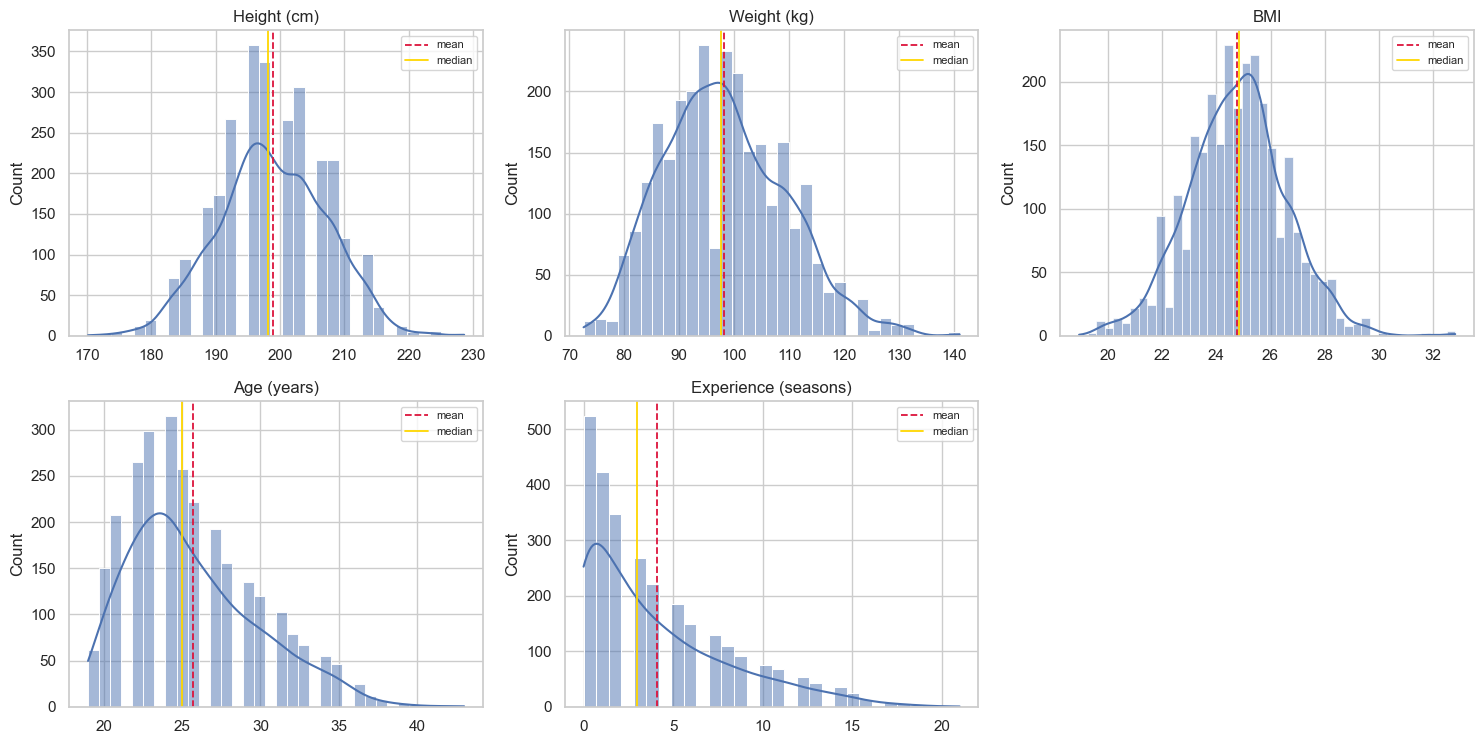

In [17]:
hist_grid(body_df, body_cols, body_labels)

<div dir="rtl" style="text-align: right;">
<h4>نمودار جعبه‌ای</h4>
</div>

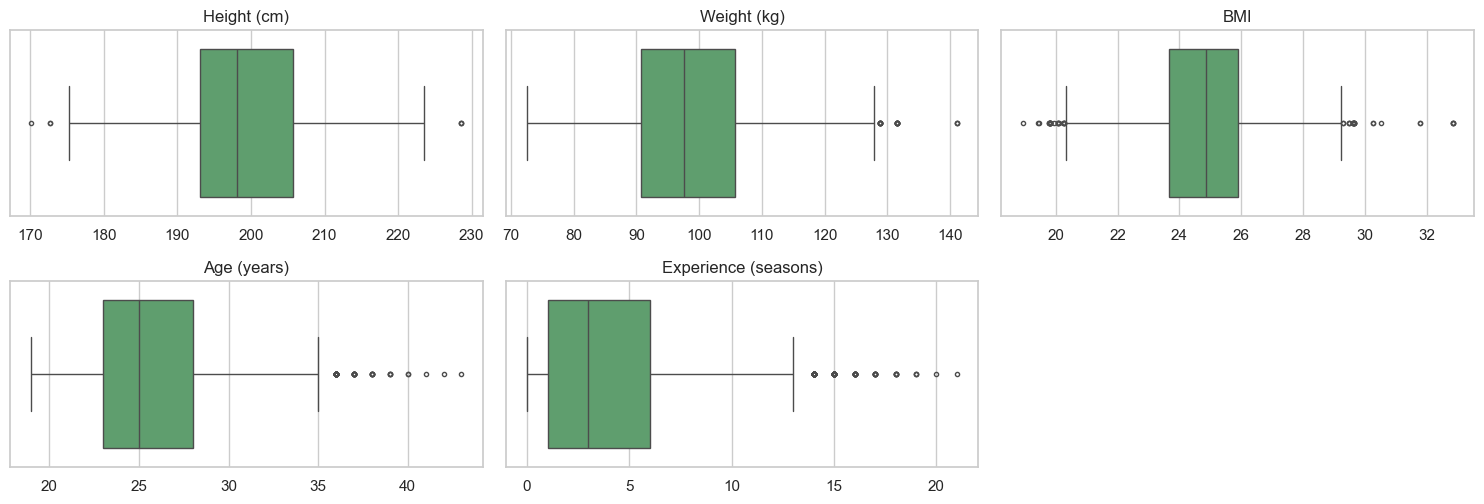

In [18]:
box_grid(body_df, body_cols, body_labels)

<div dir="rtl" style="text-align: right;">
<h4>نمودار Q-Q</h4>
</div>

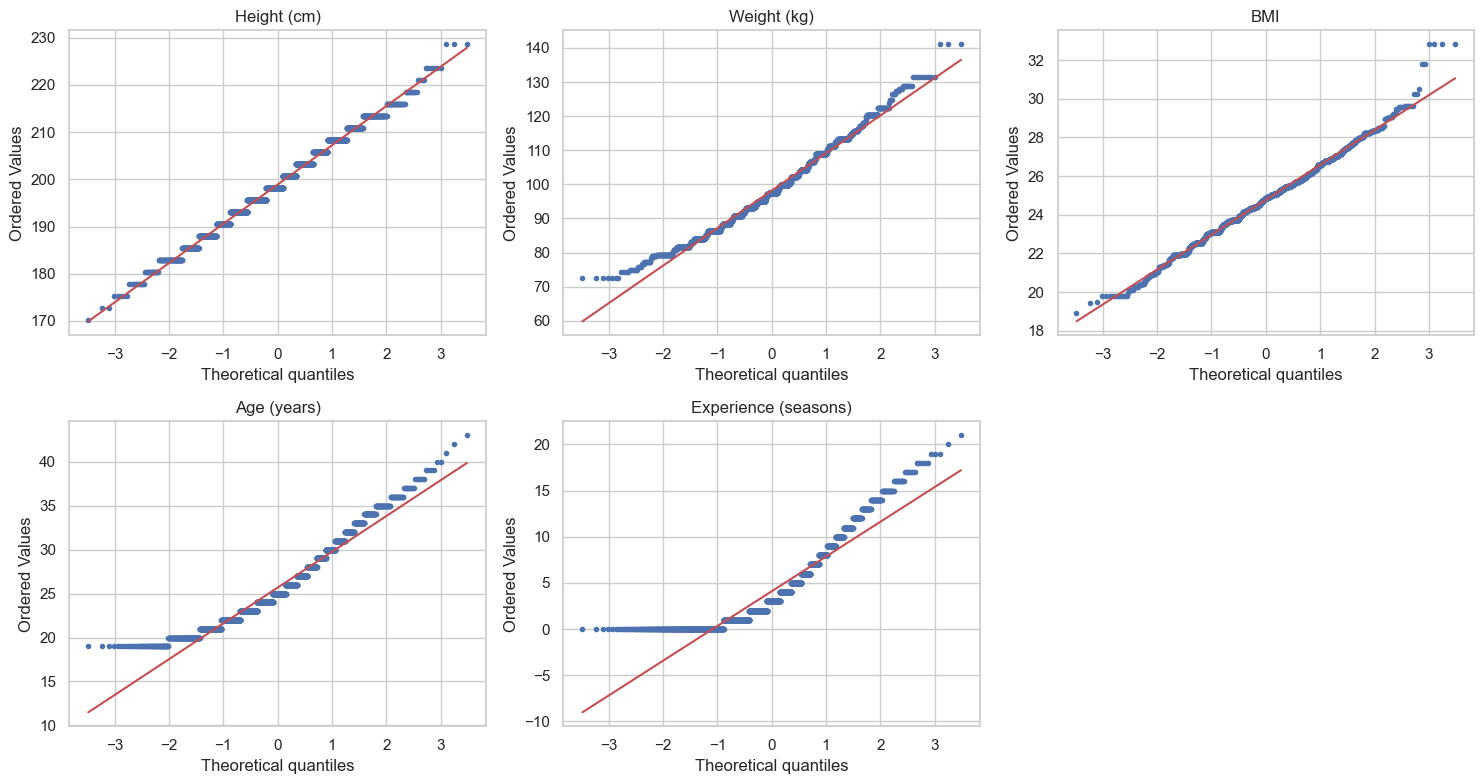

In [19]:
qq_grid(body_df, body_cols, body_labels)

<div dir="rtl" style="text-align: right;">
<p>قد تنها متغیری است که نرمال می‌ماند (چولگی ۰٫۰۱ و p-value برابر ۰٫۲۶). وزن کمی راست‌چوله است و سن و سابقه راست‌چوله‌اند، چون بازیکن جوان زیاد و بازیکن باتجربه کم داریم. آزمون نرمال‌بودن برای بقیه رد می‌شود.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h4>متغیرهای دسته‌ای: پست و سابقه</h4>
</div>

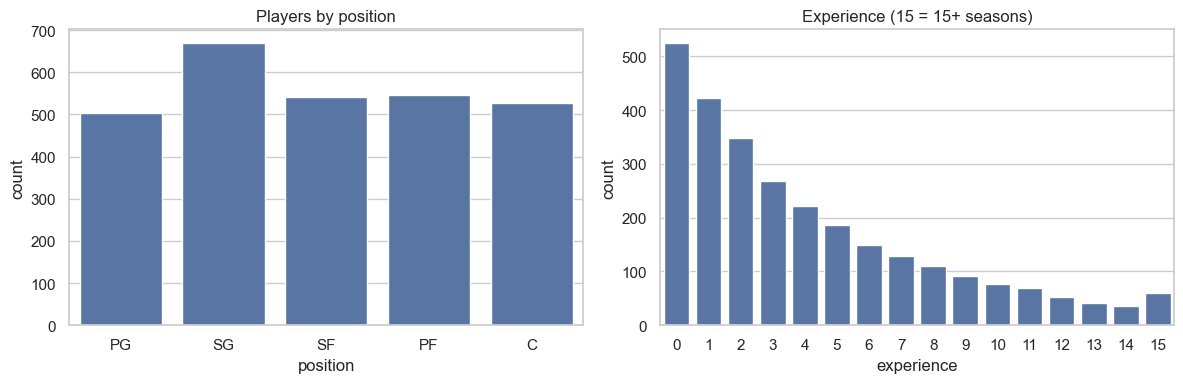

position
SG   0.240
PF   0.196
SF   0.194
C    0.189
PG   0.181
Name: proportion, dtype: float64

In [20]:
position_order = ['PG', 'SG', 'SF', 'PF', 'C']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='position', data=body_df, order=position_order, ax=axes[0])
axes[0].set_title('Players by position')
sns.countplot(x='experience', data=body_df.assign(experience=body_df['experience'].clip(upper=15)), ax=axes[1])
axes[1].set_title('Experience (15 = 15+ seasons)')
fig.tight_layout()
plt.show()
body_df['position'].value_counts(normalize=True).round(3)

<div dir="rtl" style="text-align: right;">
<h4>قد بازیکنان در پنج فصل</h4>
</div>

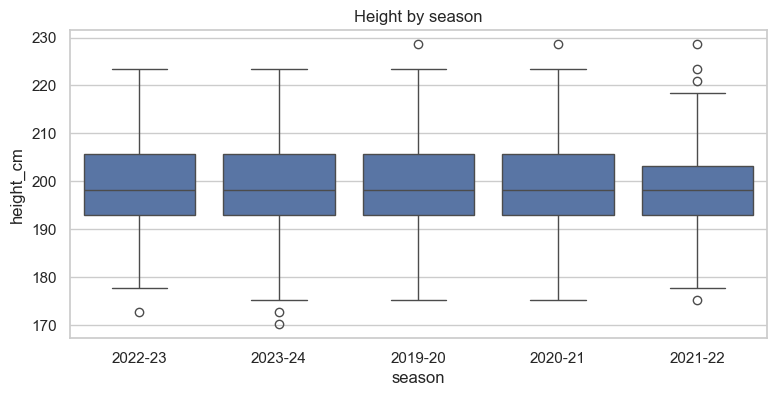

,count,mean,median,std
season,,,,
2019-20,529,198.930,198.120,8.610
2020-21,540,198.890,198.120,8.520
2021-22,605,198.400,198.120,8.390
2022-23,539,199.100,198.120,8.130
2023-24,572,199.150,198.120,8.130


In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(x='season', y='height_cm', data=body_df, ax=ax, color='#4c72b0')
ax.set_title('Height by season')
plt.show()
body_df.groupby('season').height_cm.agg(['count', 'mean', 'median', 'std']).round(2)

<div dir="rtl" style="text-align: right;">
<p>میانگین قد در هر پنج فصل بین ۱۹۸٫۴ تا ۱۹۹٫۲ سانتی‌متر است، پس می‌شود فصل‌ها را برای تحلیل قد با هم ادغام کرد.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h3 style="color:#28b463; border-right:5px solid #28b463; padding-right:10px;">4.2 عملکرد بازیکنان</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h4>آماده‌سازی آمار عملکرد</h4>
</div>

In [22]:
perf = body_df.copy()
perf['ppg'] = perf['points'] / perf['games_played']
perf['rpg'] = perf['total_rebounds'] / perf['games_played']
perf['apg'] = perf['assists'] / perf['games_played']
perf['spg'] = perf['steals'] / perf['games_played']
perf['bpg'] = perf['blocks'] / perf['games_played']
perf['mpg'] = perf['minutes_played'] / perf['games_played']
perf['true_shooting'] = perf['points'] / (2 * (perf['field_goal_attempts'] + 0.44 * perf['free_throw_attempts']))
perf_labels = {'mpg': 'Minutes per game', 'ppg': 'Points per game', 'rpg': 'Rebounds per game',
               'apg': 'Assists per game', 'spg': 'Steals per game', 'bpg': 'Blocks per game',
               'player_efficiency_rating': 'PER', 'true_shooting': 'TS%',
               'usage_percentage': 'USG%', 'win_shares': 'Win Shares',
               'win_shares_per_48_minutes': 'WS/48', 'box_plus_minus': 'BPM',
               'value_over_replacement_player': 'VORP'}
perf_cols = list(perf_labels)
perf.shape

(2785, 33)

<div dir="rtl" style="text-align: right;">
<h4>توزیع دقیقه بازی و فیلتر ۱۰۰۰ دقیقه</h4>
</div>

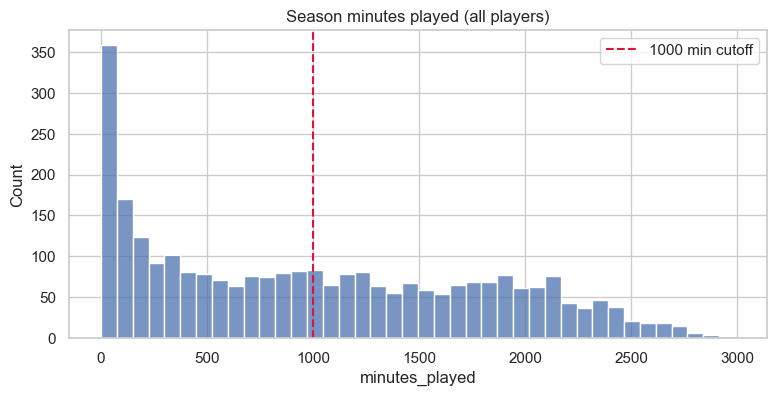

2785 1298 0.466


In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(perf.minutes_played, bins=40, ax=ax, color='#4c72b0', edgecolor='white')
ax.axvline(1000, color='crimson', ls='--', label='1000 min cutoff')
ax.set_title('Season minutes played (all players)')
ax.legend()
plt.show()
qualified = perf[perf.minutes_played >= 1000]
print(len(perf), len(qualified), round(len(qualified) / len(perf), 3))

<div dir="rtl" style="text-align: right;">
<h4>آمار توصیفی عملکرد (بازیکنان با حداقل ۱۰۰۰ دقیقه)</h4>
</div>

In [24]:
describe_cols(qualified, perf_cols, perf_labels)

,n,mean,median,std,min,q1,q3,max,cv,skew,kurtosis,outliers,normaltest_p
variable,,,,,,,,,,,,,
Minutes per game,1298,27.125,27.680,5.754,13.944,22.418,32.042,37.912,0.212,-0.205,-1.020,0,0.000
Points per game,1298,13.352,11.704,6.229,3.420,8.596,17.194,34.692,0.467,0.877,0.139,14,0.000
Rebounds per game,1298,4.918,4.321,2.445,0.833,3.200,5.971,15.158,0.497,1.251,1.493,63,0.000
Assists per game,1298,2.994,2.338,2.019,0.312,1.457,4.100,11.738,0.674,1.275,1.397,33,0.000
Steals per game,1298,0.849,0.800,0.340,0.169,0.598,1.047,2.161,0.401,0.801,0.648,26,0.000
Blocks per game,1298,0.531,0.405,0.451,0.000,0.238,0.660,3.577,0.850,2.292,7.340,78,0.000
PER,1298,15.327,14.700,4.514,3.700,12.000,17.900,34.100,0.294,0.849,0.871,25,0.000
TS%,1298,0.578,0.575,0.047,0.430,0.546,0.605,0.745,0.082,0.389,0.503,24,0.000
USG%,1298,20.060,19.200,5.789,6.500,15.800,23.775,39.600,0.289,0.566,-0.123,11,0.000


<div dir="rtl" style="text-align: right;">
<h4>هیستوگرام و نمودار چگالی</h4>
</div>

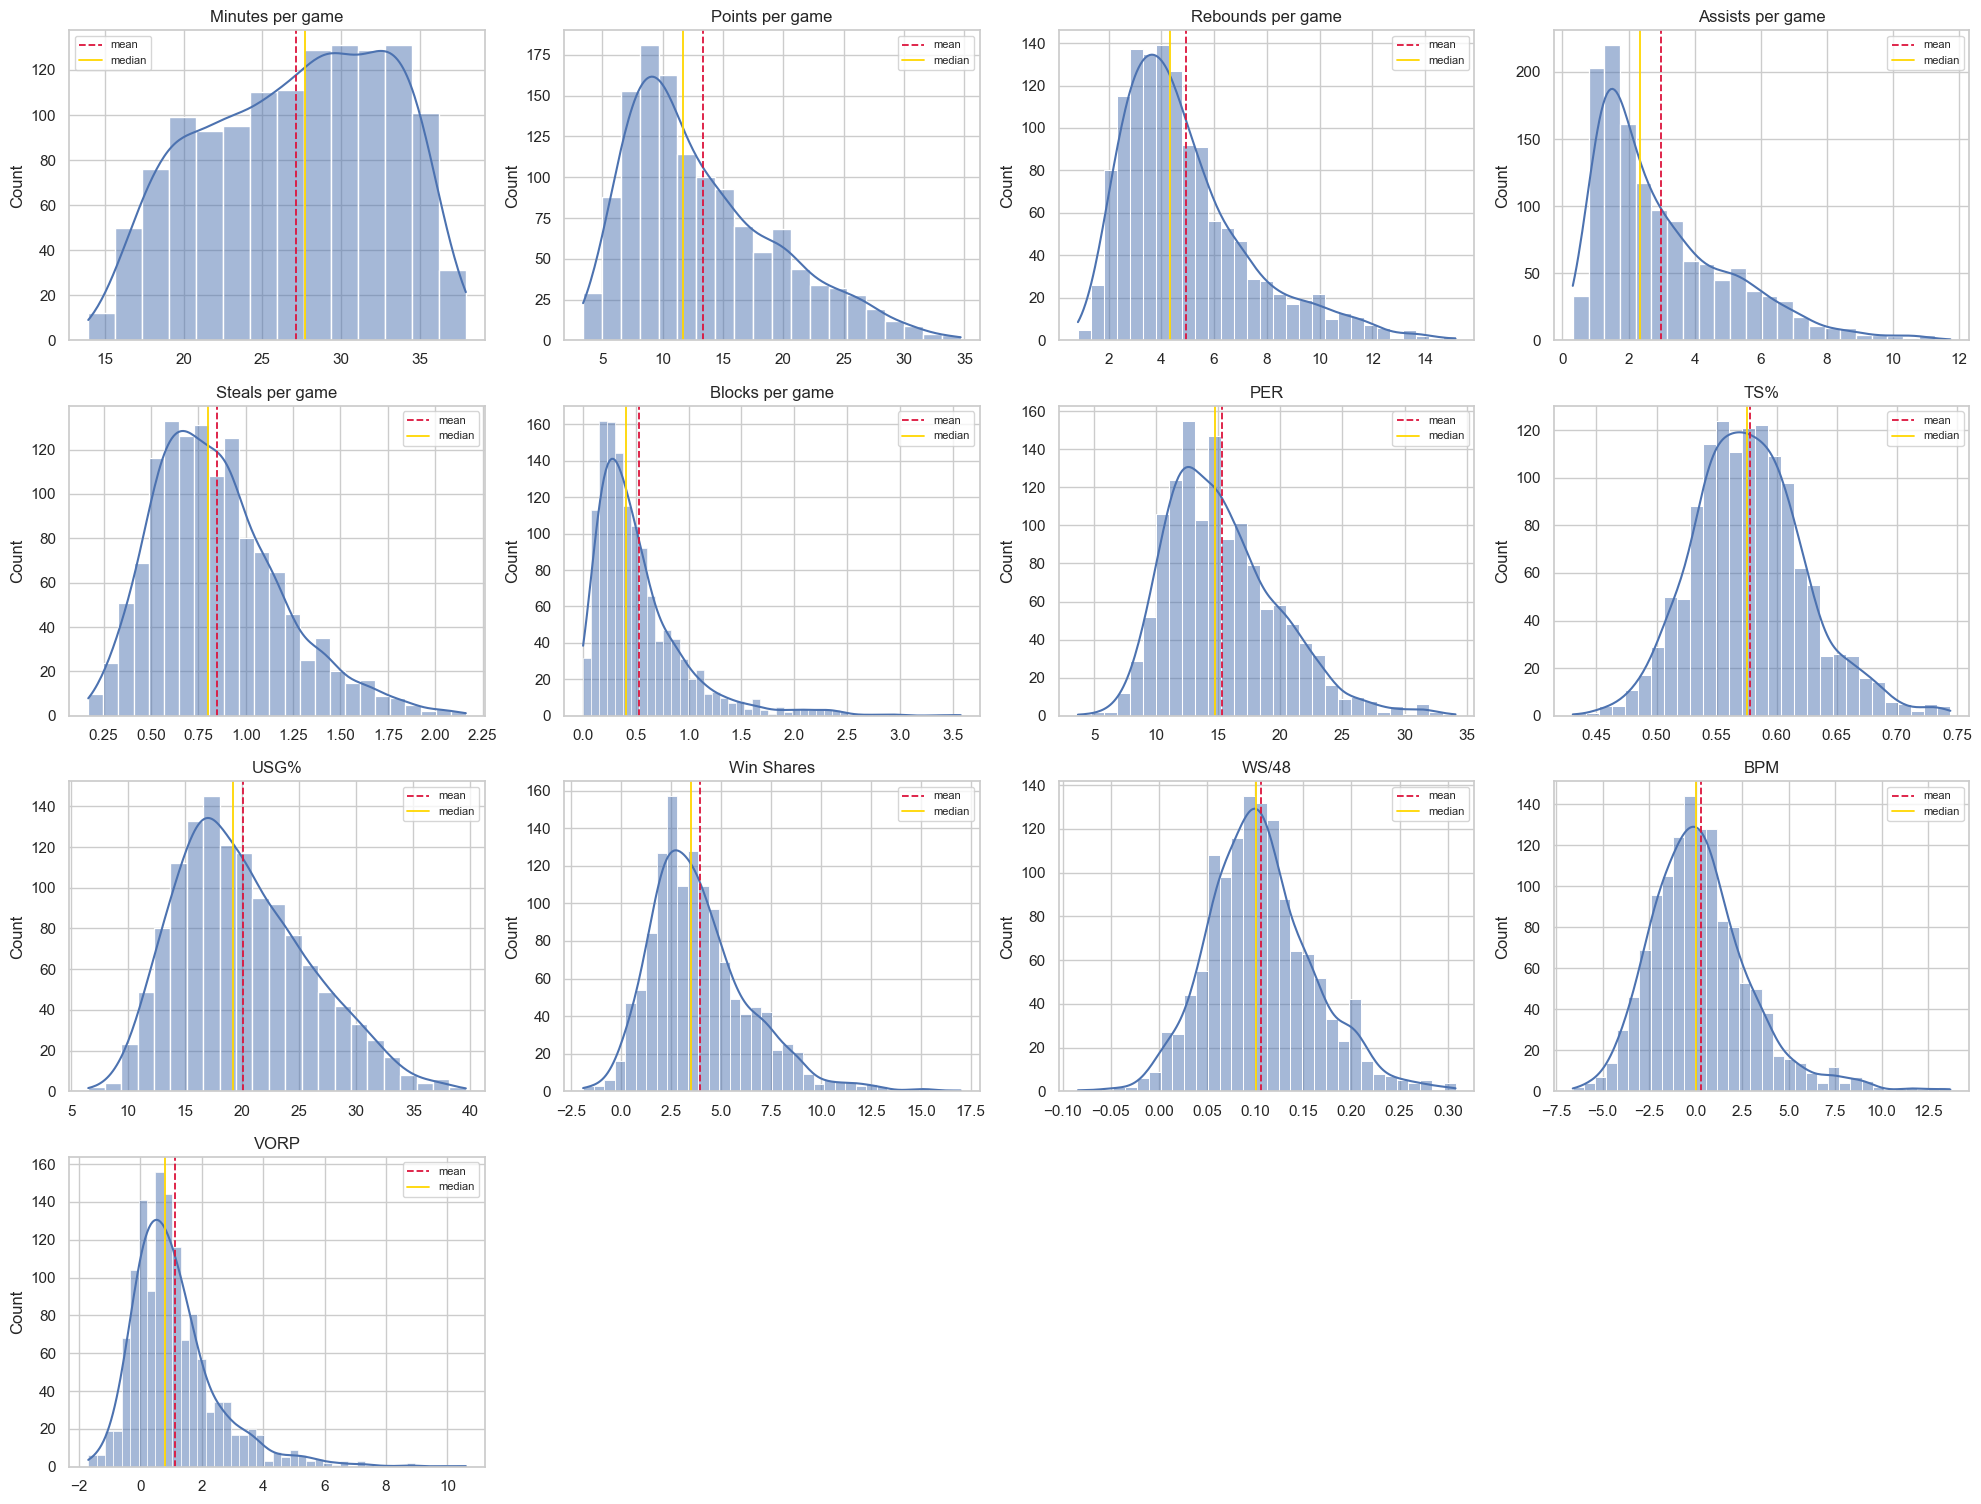

In [25]:
hist_grid(qualified, perf_cols, perf_labels, ncols=4)

<div dir="rtl" style="text-align: right;">
<h4>نمودار جعبه‌ای</h4>
</div>

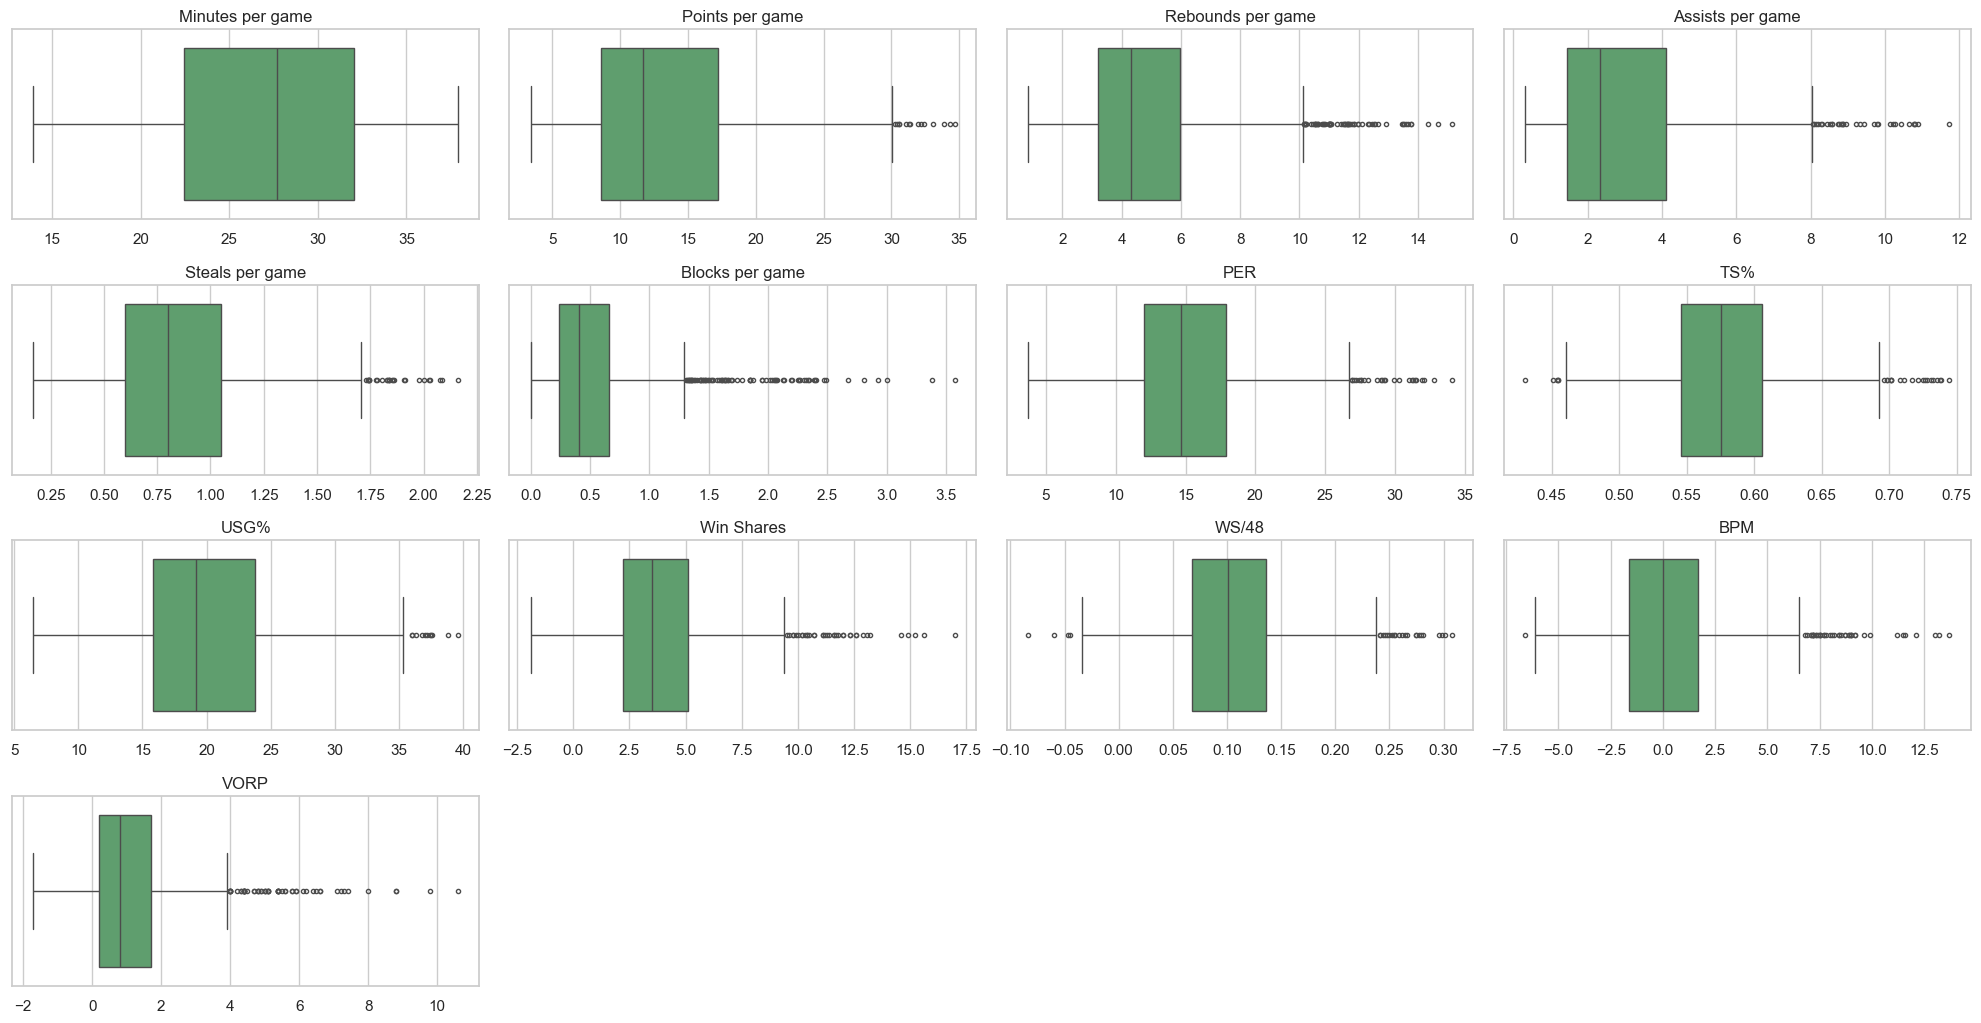

In [26]:
box_grid(qualified, perf_cols, perf_labels, ncols=4)

<div dir="rtl" style="text-align: right;">
<h4>چولگی متغیرها</h4>
</div>

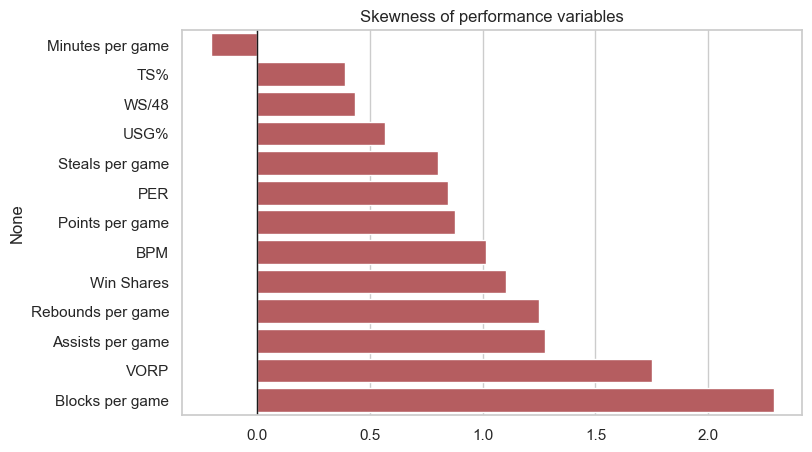

In [27]:
skew = qualified[perf_cols].skew().rename(index=perf_labels).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=skew.values, y=skew.index, ax=ax, color='#c44e52')
ax.axvline(0, color='k', lw=1)
ax.set_title('Skewness of performance variables')
plt.show()

<div dir="rtl" style="text-align: right;">
<p>آمار شمارشی (امتیاز، ریباند، پاس، بلاک) راست‌چوله است، چون چند ستاره در دم راست هستند. بلاک بیشترین چولگی (۲٫۳) را دارد. دقیقه بازی و TS% تقریباً قرینه‌اند. فقط حدود ۴۷٪ بازیکن‌ها حداقل ۱۰۰۰ دقیقه بازی کرده‌اند.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h3 style="color:#28b463; border-right:5px solid #28b463; padding-right:10px;">4.3 تیم‌ها و قهرمانان</h3>
</div>

<div dir="rtl" style="text-align: right;">

تیم‌ها را با جمع Win Shares بازیکنانشان در فصل عادی مقایسه می‌کنیم.
جمع Win Shares یک تیم تقریباً همان تعداد بردهای آن تیم است.

</div>

In [28]:
team_query = '''
SELECT
    s.season_label AS season,
    t.scope_code AS team,
    t.team_name,
    s.champion_team_code,
    COUNT(*) AS players,
    SUM(f.win_shares) AS team_win_shares,
    MAX(f.win_shares) AS best_player_ws
FROM fact_player_stats AS f
JOIN dim_season AS s ON s.season_key = f.season_key
JOIN dim_team_scope AS t ON t.scope_key = f.scope_key
WHERE f.phase_key = 1
  AND t.scope_kind = 'team'
GROUP BY s.season_label, t.scope_code, t.team_name, s.champion_team_code
'''

with engine.connect() as connection:
    team_seasons = pd.read_sql_query(text(team_query), connection)

team_seasons['is_champion'] = team_seasons['team'] == team_seasons['champion_team_code']
team_seasons['ws_rank'] = team_seasons.groupby('season')['team_win_shares'].rank(ascending=False)
team_seasons['star_share'] = team_seasons['best_player_ws'] / team_seasons['team_win_shares']

print('teams per season:', team_seasons.groupby('season').size().to_dict())
team_seasons[team_seasons['is_champion']][['season', 'team_name', 'team_win_shares', 'ws_rank', 'best_player_ws', 'star_share']].round(3)

teams per season: {'2019-20': 30, '2020-21': 30, '2021-22': 30, '2022-23': 30, '2023-24': 30}


,season,team_name,team_win_shares,ws_rank,best_player_ws,star_share
13,2019-20,Los Angeles Lakers,47.700,6.000,11.100,0.233
46,2020-21,Milwaukee Bucks,48.000,5.000,10.200,0.212
69,2021-22,Golden State Warriors,55.300,5.000,8.000,0.145
97,2022-23,Denver Nuggets,49.300,7.000,14.900,0.302
121,2023-24,Boston Celtics,67.600,1.000,10.400,0.154


In [29]:
fig = px.strip(team_seasons, x='season', y='team_win_shares', color='is_champion', hover_name='team_name',
               color_discrete_map={True: '#d9631e', False: '#7f8c9a'},
               title='Team win shares by season (champions in orange)',
               labels={'season': 'Season', 'team_win_shares': 'Team win shares', 'is_champion': 'Champion'})
fig.show()

champion_share = team_seasons.loc[team_seasons['is_champion'], 'star_share']
other_share = team_seasons.loc[~team_seasons['is_champion'], 'star_share']
print('median star share: champions', round(champion_share.median(), 3), '| others', round(other_share.median(), 3))
print('Mann-Whitney p =', round(stats.mannwhitneyu(champion_share, other_share).pvalue, 4))

median star share: champions 0.212 | others 0.194
Mann-Whitney p = 0.9666


<div dir="rtl" style="text-align: right;">

قهرمان‌ها لزوماً بهترین تیم فصل عادی نبودند.
در جمع Win Shares، لیکرز 2019-20 ششم، باکس و واریرز پنجم و دنور 2022-23 هفتم لیگ بودند؛ فقط بوستون 2023-24 اول بود.

وابستگی به یک ستاره هم در قهرمان‌ها با بقیه فرقی ندارد.
دنور با یوکیچ بیشترین وابستگی را داشت (0.30) و گلدن استیت کمترین (0.15).

</div>

<div dir="rtl" style="text-align: right;">
<h3 style="color:#28b463; border-right:5px solid #28b463; padding-right:10px;">4.4 رابطه میان آمار بازیکنان</h3>
</div>

<div dir="rtl" style="text-align: right;">

آیا قدبلندتر بودن واقعاً ریباند بیشتر می آورد؟ و کسی که توپ بیشتری دستش است دقیق تر هم شوت می زند یا فقط بیشتر امتیاز می گیرد؟

#### خواندن داده

</div>

In [30]:
stats_query = '''
SELECT
    p.player_key,
    p.player_name,
    s.season_label AS season,
    c.position_code AS position,
    c.reported_age AS age,
    c.experience_years,
    p.listed_height_inches,
    p.listed_weight_pounds,
    f.games_played,
    f.minutes_played,
    f.points,
    f.total_rebounds,
    f.assists,
    f.field_goal_attempts,
    f.three_point_attempts,
    f.free_throw_attempts,
    f.usage_percentage,
    f.box_plus_minus,
    f.win_shares,
    sal.annual_salary_usd
FROM fact_player_stats AS f
JOIN dim_player AS p ON p.player_key = f.player_key
JOIN dim_season AS s ON s.season_key = f.season_key
JOIN dim_player_context AS c ON c.context_key = f.context_key
LEFT JOIN fact_player_salary AS sal
    ON sal.player_key = f.player_key AND sal.season_key = f.season_key
WHERE f.phase_key = 1
  AND f.is_player_phase_total = 1
'''

with engine.connect() as connection:
    player_stats = pd.read_sql_query(text(stats_query), connection)

print(player_stats.shape)
player_stats.head()

(2785, 20)


,player_key,player_name,season,position,age,experience_years,listed_height_inches,listed_weight_pounds,games_played,minutes_played,points,total_rebounds,assists,field_goal_attempts,three_point_attempts,free_throw_attempts,usage_percentage,box_plus_minus,win_shares,annual_salary_usd
0,1,A.J. Green,2022-23,SG,23,0,76,190,35,345,154,45,22,125,105,4,16.600,-0.900,0.800,NaN
1,1,A.J. Green,2023-24,SG,24,1,76,190,56,614,252,64,30,196,169,19,15.200,-2.100,1.100,1901769.000
2,2,A.J. Lawson,2022-23,SG,22,0,78,179,15,108,56,21,2,44,25,8,21.100,-4.400,0.100,NaN
3,2,A.J. Lawson,2023-24,SG,23,1,78,179,42,311,136,50,20,121,50,23,20.000,-4.600,0.200,1000000.000
4,3,AJ Griffin,2022-23,SF,19,0,78,220,72,1401,639,153,73,533,259,47,17.900,-0.800,2.200,3536160.000


<div dir="rtl" style="text-align: right;">

#### تمیز کردن داده


</div>

In [31]:
print('duplicates:', player_stats.duplicated(['player_key', 'season']).sum())
nulls = player_stats.isna().sum()
nulls[nulls > 0]

duplicates: 0


annual_salary_usd    285
dtype: int64

<div dir="rtl" style="text-align: right;">

ردیف تکراری نداریم.

بازیکنی که 3 بازی و هر بازی 5 دقیقه بازی کرده، با یک شوت خوب یا بد درصدش کلا عوض می شود. برای همین فقط کسانی را نگه می داریم که حداقل 20 بازی کرده اند و در هر بازی حداقل 15 دقیقه روی زمین بوده اند.

</div>

In [32]:
MIN_GAMES = 20
MIN_MINUTES_PER_GAME = 15

df = player_stats.copy()
df['minutes_per_game'] = df['minutes_played'] / df['games_played']
df = df[(df['games_played'] >= MIN_GAMES) & (df['minutes_per_game'] >= MIN_MINUTES_PER_GAME)].copy()

print(len(player_stats), '->', len(df))
print('nulls left:', df[['usage_percentage', 'box_plus_minus']].isna().sum().sum())

2785 -> 1645
nulls left: 0


<div dir="rtl" style="text-align: right;">

ستون خالی بعد از فیلتر نداریم.

حالا ستون هایی می سازیم که قابل مقایسه باشند: قد و وزن به سانتی متر و کیلوگرم، و آمار به صورت میانگین در هر بازی (چون تعداد بازی ها فرق می کند).

دو ستون دیگر هم اضافه می کنیم: `three_point_rate` که سهم پرتاب های سه امتیازی از کل پرتاب هاست، و `true_shooting` که دقت شوت را با حساب پرتاب آزاد نشان می دهد.

</div>

In [33]:
df['height_cm'] = (df['listed_height_inches'] * 2.54).round(1)
df['weight_kg'] = (df['listed_weight_pounds'] * 0.4536).round(1)
df['points_per_game'] = df['points'] / df['games_played']
df['rebounds_per_game'] = df['total_rebounds'] / df['games_played']
df['assists_per_game'] = df['assists'] / df['games_played']
df['three_point_rate'] = df['three_point_attempts'] / df['field_goal_attempts']
df['true_shooting'] = df['points'] / (2 * (df['field_goal_attempts'] + 0.44 * df['free_throw_attempts']))

NUMERIC_COLUMNS = [
    'height_cm', 'weight_kg', 'age', 'experience_years', 'minutes_per_game',
    'points_per_game', 'rebounds_per_game', 'assists_per_game',
    'three_point_rate', 'true_shooting', 'usage_percentage', 'box_plus_minus',
]
df[NUMERIC_COLUMNS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
height_cm,1645.000,198.870,8.070,172.700,193.000,198.100,203.200,223.500
weight_kg,1645.000,98.660,10.920,72.600,90.700,97.500,106.600,131.500
age,1645.000,26.240,4.260,19.000,23.000,26.000,29.000,39.000
experience_years,1645.000,5.100,4.020,0.000,2.000,4.000,8.000,20.000
minutes_per_game,1645.000,25.470,6.300,15.000,19.780,25.580,30.880,37.910
points_per_game,1645.000,12.130,6.220,1.680,7.410,10.290,15.430,34.690
rebounds_per_game,1645.000,4.620,2.350,1.120,2.950,4.100,5.620,15.160
assists_per_game,1645.000,2.730,1.950,0.230,1.270,2.070,3.640,11.740
three_point_rate,1645.000,0.400,0.200,0.000,0.280,0.410,0.530,0.900
true_shooting,1645.000,0.570,0.050,0.360,0.540,0.570,0.600,0.780


<div dir="rtl" style="text-align: right;">

#### چولگی

چولگی نشان می دهد توزیع به یک طرف کشیده شده یا نه

</div>

In [34]:
skew_table = pd.DataFrame({
    'mean': df[NUMERIC_COLUMNS].mean(),
    'median': df[NUMERIC_COLUMNS].median(),
    'skew': df[NUMERIC_COLUMNS].skew(),
})
skew_table['shape'] = np.where(skew_table['skew'] > 0.5, 'right skewed',
                               np.where(skew_table['skew'] < -0.5, 'left skewed', 'about symmetric'))
skew_table.sort_values('skew', ascending=False).round(3)

,mean,median,skew,shape
assists_per_game,2.728,2.070,1.401,right skewed
rebounds_per_game,4.618,4.097,1.341,right skewed
points_per_game,12.126,10.293,1.028,right skewed
experience_years,5.098,4.000,0.823,right skewed
box_plus_minus,-0.160,-0.400,0.763,right skewed
usage_percentage,19.442,18.500,0.624,right skewed
age,26.244,26.000,0.441,about symmetric
weight_kg,98.663,97.500,0.349,about symmetric
true_shooting,0.572,0.571,0.177,about symmetric
minutes_per_game,25.466,25.577,0.041,about symmetric


<div dir="rtl" style="text-align: right;">

نتیجه ی جدول: امتیاز (1.03)، ریباند (1.34) و پاس گل (1.40) چوله به راست هستند، یعنی بیشتر بازیکن ها عدد کوچکی دارند و چند ستاره عددهای خیلی بزرگ.
</div>

In [35]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def histogram_with_box(values, title, x_title, bins=30):
    fig = make_subplots(rows=1, cols=2, column_widths=[0.8, 0.2], horizontal_spacing=0.06)
    fig.add_trace(go.Histogram(x=values, nbinsx=bins), row=1, col=1)
    fig.add_trace(go.Box(y=values, boxpoints='outliers'), row=1, col=2)
    fig.update_xaxes(title_text=x_title, row=1, col=1)
    fig.update_yaxes(title_text='Count', row=1, col=1)
    fig.update_layout(title=title, showlegend=False)
    return fig


histogram_with_box(df['points_per_game'], 'Points per game', 'Points per game', bins=40).show()
histogram_with_box(df['height_cm'], 'Height', 'Height (cm)').show()

<div dir="rtl" style="text-align: right;">

#### داده ی پرت

با روش <span dir="ltr">IQR</span> پیش میریم

</div>

In [36]:
outlier_counts = {}
for col in NUMERIC_COLUMNS:
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    outlier_counts[col] = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()

pd.Series(outlier_counts, name='outliers').sort_values(ascending=False)

rebounds_per_game    83
assists_per_game     58
box_plus_minus       52
true_shooting        38
points_per_game      35
usage_percentage     16
experience_years      5
height_cm             5
weight_kg             4
age                   1
minutes_per_game      0
three_point_rate      0
Name: outliers, dtype: int64

In [37]:
df.nlargest(5, 'points_per_game')[['season', 'player_name', 'points_per_game', 'box_plus_minus']]

,season,player_name,points_per_game,box_plus_minus
1343,2023-24,Joel Embiid,34.692,11.600
1179,2019-20,James Harden,34.338,9.600
1772,2023-24,Luka Dončić,33.857,9.900
1342,2022-23,Joel Embiid,33.076,9.200
1771,2022-23,Luka Dončić,32.394,8.900


<div dir="rtl" style="text-align: right;">

بیشترین پرت در ریباند (83) و پاس گل (58).

این داده ها پرت نیستند و بازیکنان برتر هستند پس نباید حذفشون بکنیم.

#### نرمال بودن

</div>

In [38]:
ALPHA = 0.05

normality = []
for col in NUMERIC_COLUMNS:
    p = stats.shapiro(df[col]).pvalue
    normality.append({'column': col, 'shapiro_p': p, 'normal': p > ALPHA})

pd.DataFrame(normality)

,column,shapiro_p,normal
0,height_cm,0.000,False
1,weight_kg,0.000,False
2,age,0.000,False
3,experience_years,0.000,False
4,minutes_per_game,0.000,False
5,points_per_game,0.000,False
6,rebounds_per_game,0.000,False
7,assists_per_game,0.000,False
8,three_point_rate,0.000,False
9,true_shooting,0.000,False


<div dir="rtl" style="text-align: right;">

تقریباً هیچ ستونی نرمال نیست. برای همین <span dir="ltr">Spearman</span> را معیار می گیریم
#### همبستگی عددی با عددی

</div>

In [39]:
corr_matrix = df[NUMERIC_COLUMNS].corr(method='spearman')

fig = px.imshow(corr_matrix, text_auto='.2f', color_continuous_scale='RdBu', zmin=-1, zmax=1, aspect='auto',
                title='Spearman correlation')
fig.update_layout(height=650)
fig.show()

In [40]:
upper = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)
strongest = corr_matrix.where(upper).stack().sort_values(key=abs, ascending=False)
strongest.head(10).round(3)

age               experience_years    0.894
minutes_per_game  points_per_game     0.872
points_per_game   usage_percentage    0.830
height_cm         weight_kg           0.768
minutes_per_game  assists_per_game    0.664
height_cm         rebounds_per_game   0.618
points_per_game   assists_per_game    0.613
weight_kg         rebounds_per_game   0.590
true_shooting     box_plus_minus      0.577
assists_per_game  usage_percentage    0.555
dtype: float64

<div dir="rtl" style="text-align: right;">

از بین این جفت ها چندتا را که برای بسکتبال معنی دارند جدا آزمون می کنیم

فرض صفر هر آزمون این است که رابطه ای نیست

</div>

In [41]:
POSITIONS = ['PG', 'SG', 'SF', 'PF', 'C']

PAIRS = [
    ('height_cm', 'rebounds_per_game'),
    ('height_cm', 'assists_per_game'),
    ('height_cm', 'three_point_rate'),
    ('usage_percentage', 'points_per_game'),
    ('usage_percentage', 'true_shooting'),
    ('age', 'box_plus_minus'),
    ('experience_years', 'box_plus_minus'),
]

rows = []
for x, y in PAIRS:
    pearson_r, pearson_p = stats.pearsonr(df[x], df[y])
    spearman_rho, spearman_p = stats.spearmanr(df[x], df[y])
    rows.append({'x': x, 'y': y, 'pearson_r': pearson_r, 'pearson_p': pearson_p,
                 'spearman_rho': spearman_rho, 'spearman_p': spearman_p, 'related': spearman_p < ALPHA})

pair_results = pd.DataFrame(rows)
pair_results.round(4)

,x,y,pearson_r,pearson_p,spearman_rho,spearman_p,related
0,height_cm,rebounds_per_game,0.614,0.000,0.618,0.000,True
1,height_cm,assists_per_game,-0.352,0.000,-0.401,0.000,True
2,height_cm,three_point_rate,-0.382,0.000,-0.348,0.000,True
3,usage_percentage,points_per_game,0.883,0.000,0.830,0.000,True
4,usage_percentage,true_shooting,-0.019,0.452,-0.039,0.116,False
5,age,box_plus_minus,0.193,0.000,0.198,0.000,True
6,experience_years,box_plus_minus,0.262,0.000,0.284,0.000,True


<div dir="rtl" style="text-align: right;">

نتیجه ی جدول: در هر هفت جفت <span dir="ltr">Pearson</span> و <span dir="ltr">Spearman</span> هم جهت و نزدیک به هم هستند.

فقط درصد استفاده از توپ و <span dir="ltr">TS%</span> رابطه ی معناداری ندارد (<span dir="ltr">p</span> = 0.12) و بقیه معنادارند. قد و ریباند 0.62، قد و پاس گل -0.40، قد و سهم سه امتیازی -0.35، درصد استفاده از توپ و امتیاز 0.83، تجربه و <span dir="ltr">BPM</span> 0.28 و سن و <span dir="ltr">BPM</span> 0.20 است.

</div>

In [42]:
fig = px.scatter(df, x='height_cm', y='rebounds_per_game', color='position', opacity=0.6, hover_name='player_name',
                 trendline='ols', trendline_scope='overall', category_orders={'position': POSITIONS},
                 title='Height vs rebounds per game')
fig.show()

fig = px.scatter(df, x='usage_percentage', y='true_shooting', opacity=0.5, hover_name='player_name',
                 trendline='ols', title='Usage vs true shooting')
fig.show()

<div dir="rtl" style="text-align: right;">

#### پست و آمار (دسته ای با عددی)

 برای مقایسه ی بیشتر از دو گروه <span dir="ltr">ANOVA</span> داریم و نسخه ی ناپارامتری اش <span dir="ltr">Kruskal</span>. چون داده نرمال نیست <span dir="ltr">Kruskal</span> را استفاده میکنیم و ملاک قرار میدیم

</div>

In [43]:
rows = []
for col in ['height_cm', 'rebounds_per_game', 'assists_per_game', 'three_point_rate', 'box_plus_minus']:
    groups = [df.loc[df['position'] == pos, col] for pos in POSITIONS]
    row = {'column': col}
    for pos, g in zip(POSITIONS, groups):
        row[pos] = g.median()
    row['anova_p'] = stats.f_oneway(*groups).pvalue
    row['kruskal_p'] = stats.kruskal(*groups).pvalue
    rows.append(row)

pd.DataFrame(rows).round(3)

,column,PG,SG,SF,PF,C,anova_p,kruskal_p
0,height_cm,188.000,195.600,198.100,203.200,208.300,0.000,0.000
1,rebounds_per_game,3.200,3.116,3.894,4.931,6.705,0.000,0.000
2,assists_per_game,4.596,2.235,1.699,1.657,1.344,0.000,0.000
3,three_point_rate,0.402,0.487,0.463,0.401,0.093,0.000,0.000
4,box_plus_minus,0.100,-1.000,-1.100,-0.400,0.750,0.000,0.000


<div dir="rtl" style="text-align: right;">

نتیجه ی جدول:

میانه ی قد از 188 سانتی متر در پوینت گاردها تا 208 در سنترها بالا می رود و ریباند از 3.2 تا 6.7

پاس گل برعکس است، پوینت گاردها 4.6 و سنترها 1.3. سهم سه امتیازی سنترها فقط 0.09

<span dir="ltr">p</span> هر پنج آزمون <span dir="ltr">Kruskal</span> زیر 0.001

</div>

In [44]:
fig = px.box(df, x='position', y='assists_per_game', color='position', category_orders={'position': POSITIONS},
             title='Assists per game by position')
fig.show()

fig = px.box(df, x='position', y='three_point_rate', color='position', category_orders={'position': POSITIONS},
             title='3PA rate by position')
fig.show()

<div dir="rtl" style="text-align: right;">

#### پست و سه امتیازی زن بودن (دسته ای با دسته ای)

بازیکنی را سه امتیازی زن می گیریم که حداقل 40 درصد پرتاب هایش سه امتیازی باشد

</div>

In [45]:
df['shooter'] = np.where(df['three_point_rate'] >= 0.4, '3PT shooter', 'other')
table = pd.crosstab(df['position'], df['shooter']).reindex(POSITIONS)

chi2, p_value, dof, expected = stats.chi2_contingency(table)
print(f'chi2 = {chi2:.1f}, dof = {dof}, p = {p_value:.3g}')

table['share'] = (table['3PT shooter'] / table.sum(axis=1)).round(3)
table

chi2 = 257.9, dof = 4, p = 1.32e-54


shooter,3PT shooter,other,share
position,,,
PG,162,155,0.511
SG,286,99,0.743
SF,206,110,0.652
PF,162,159,0.505
C,49,257,0.160


<div dir="rtl" style="text-align: right;">

نتیجه ی آزمون:

 <span dir="ltr">p</span> خیلی کوچک است، پس پست و سه امتیازی زن بودن مستقل نیستند.

سهم سه امتیازی زن ها در شوتینگ گارد 74 درصد، سمال فوروارد 65، پوینت گارد 51، پاور فوروارد 51 و سنتر 16 درصد است.

</div>

In [46]:
fig = px.bar(table.reset_index(), x='position', y='share', text_auto='.0%',
             title='Share of 3PT shooters by position')
fig.show()

<div dir="rtl" style="text-align: right;">

#### جمع بندی 4.4

از 2785 بازیکن-فصل بعد از فیلتر 1645 ردیف ماند. امتیاز و ریباند و پاس چوله به راست بودند چون چند ستاره میانگین را بالا می برند، ولی قد و <span dir="ltr">TS%</span> و دقیقه تقریباً متقارن بودند. هیچ ستونی نرمال نبود و برای همین <span dir="ltr">Spearman</span> و <span dir="ltr">Kruskal</span> را به کار بردیم.

قد با ریباند رابطه ی مثبت و قوی دارد (0.62) و با پاس گل (-0.40) و سهم سه امتیازی (-0.35) رابطه ی منفی. درصد استفاده از توپ با امتیاز رابطه ی خیلی قوی دارد (0.83) ولی با دقت شوت نه (<span dir="ltr">p</span> = 0.12). یعنی بازیکنی که توپ بیشتری دارد بیشتر امتیاز می گیرد، نه اینکه دقیق تر بزند. تجربه و سن هر دو رابطه ی ضعیف ولی معنادار با <span dir="ltr">BPM</span> دارند (0.28 و 0.20).

پست ها در هر پنج ستون فرق معنادار داشتند (<span dir="ltr">Kruskal</span>، <span dir="ltr">p</span> < 0.001). پوینت گاردها با میانه ی 4.6 پاس گل بیشترین پاس را دارند و سنترها تقریباً سه امتیازی نمی زنند (میانه ی 0.09). <span dir="ltr">chi-square</span> هم نشان داد پست و سه امتیازی زن بودن مستقل نیستند (χ² = 258، <span dir="ltr">p</span> < 0.001): 74 درصد شوتینگ گاردها سه امتیازی زن هستند و فقط 16 درصد سنترها.

</div>

<div dir="rtl" style="text-align: right;">
<h2 style="background:#8e44ad; color:white; padding:8px 14px; border-radius:8px;">5. معیار انتخاب بازیکنان برتر</h2>
</div>

<div dir="rtl" style="text-align: right;">

### هدف
برای هر فصل، بازیکنان را با یک **امتیاز واحد** رتبه‌بندی می‌کنیم و 50 نفر اول را انتخاب می‌کنیم.

### چرا یک امتیاز ترکیبی؟
هیچ آمار منفردی عملکرد را کامل نشان نمی‌دهد. برای مثال، مجموع امتیاز به تعداد شوت‌ها وابسته است و کیفیتِ بازی در هر دقیقه را نشان نمی‌دهد. به همین دلیل دو دیدگاه را با هم ترکیب کردیم:

- **شاخص‌های نرخی (کیفیت در هر دقیقه):**
  - **BPM** (Box Plus/Minus): تخمین امتیازی که بازیکن در هر 100 حمله نسبت به یک بازیکن متوسط اضافه می‌کند (صفر = متوسط).
  - **PER** (Player Efficiency Rating): نسبت کارهای مثبت (امتیاز، ریباند، پاس گل، سرقت، بلاک) به کارهای منفی (شوت از دست رفته، توپ‌باخت، خطا) در هر دقیقه؛ میانگین لیگ حدود 15 است.
  - **WS/48** (Win Shares per 48 minutes): سهم بازیکن در بردهای تیم به ازای 48 دقیقه؛ میانگین لیگ حدود 0.1 است.
- **شاخص حجمی (مجموع ارزش در کل فصل):**
  - **WS** (Win Shares): تعداد بردهایی که بازیکن در کل فصل برای تیمش ساخته است. این شاخص باعث می‌شود بازیکنی که نیمی از فصل را غایب بوده، فقط به خاطر نرخ بالا در صدر نیاید.

### مراحل محاسبه
1. فقط **فصل عادی** و **یک ردیف برای هر بازیکن**؛ برای بازیکنانی که وسط فصل تیم عوض کرده‌اند، ردیف مجموعِ همهٔ تیم‌ها (2TM/3TM) استفاده می‌شود.
2. فقط بازیکنان با **حداقل 1000 دقیقه** بازی؛ زیرا آمار نمونه‌های کوچک پرنوسان است و بازیکن با چند دقیقه بازیِ عالی نباید قهرمان شود.
3. **استانداردسازی (z-score)** هر شاخص در همان فصل: 
   $z(x)=\dfrac{x-\mu}{\sigma}$ 
   که $\mu$ و $\sigma$ میانگین و انحراف معیار همان شاخص بین بازیکنان واجد شرایط آن فصل است. این کار شاخص‌هایی با مقیاس‌های متفاوت را قابل جمع می‌کند.
4. محاسبهٔ امتیاز نهایی:

$$\text{Impact}=\frac{z(\text{BPM})+z(\text{PER})+z(\text{WS/48})}{3}$$

$$\text{Score}=0.6\times\text{Impact}+0.4\times z(\text{WS})$$

5. مرتب‌سازی نزولی بر اساس Score و انتخاب 50 نفر اول.

### چرا وزن‌های 0.6 و 0.4؟
کیفیت در هر دقیقه نشانهٔ اصلی توانایی است (وزن بیشتر)، ولی میزان حضور در فصل هم مهم است. این وزن‌ها یک **تصمیم قضاوتی** هستند، نه فرمول «درستِ مطلق»؛ به همین دلیل حساسیت‌سنجی انجام دادیم.


</div>


In [47]:
top50 = nba_top_players.get_top_players(engine, "2019-20")        # or just pass the path :)))
# all_years = pd.concat([nba_top_players.get_top_players(engine, s) for s in
#                        ["2019-20","2020-21","2021-22","2022-23","2023-24"]])
top50

,rank,player_key,player_name,season,team,position,games_played,minutes_played,box_plus_minus,player_efficiency_rating,win_shares_per_48_minutes,win_shares,impact_z,volume_z,score
0,1,313,Giannis Antetokounmpo,2019-20,MIL,PF,63,1917,11.500,31.900,0.279,11.100,3.602,3.201,3.442
1,2,410,James Harden,2019-20,HOU,SG,68,2483,9.600,29.100,0.254,13.100,3.014,4.071,3.437
2,3,47,Anthony Davis,2019-20,LAL,PF,62,2131,8.000,27.400,0.250,11.100,2.669,3.201,2.881
3,4,176,Damian Lillard,2019-20,POR,PG,66,2474,7.500,26.900,0.225,11.600,2.421,3.418,2.820
4,5,602,LeBron James,2019-20,LAL,PG,67,2316,8.400,25.500,0.204,9.800,2.306,2.635,2.438
5,6,539,Kawhi Leonard,2019-20,LAC,SF,57,1848,8.900,26.900,0.226,8.700,2.601,2.157,2.423
6,7,616,Luka Dončić,2019-20,DAL,PG,61,2047,8.400,27.600,0.207,8.800,2.476,2.200,2.365
7,8,722,Nikola Jokić,2019-20,DEN,C,73,2336,7.400,24.900,0.202,9.800,2.127,2.635,2.330
8,9,799,Rudy Gobert,2019-20,UTA,C,68,2333,3.600,21.700,0.221,10.700,1.537,3.027,2.133
9,10,459,Jimmy Butler,2019-20,MIA,SF,58,1959,5.400,23.600,0.221,9.000,1.898,2.287,2.053


<div dir="rtl" style="text-align: right;">
<h2 style="background:#d35400; color:white; padding:8px 14px; border-radius:8px;">6. آمار توصیفی: سؤال‌های پروژه</h2>
<h3 style="color:#d35400; border-right:5px solid #d35400; padding-right:10px;">6.1 سؤال ۱: توزیع قد بازیکنان لیست Michael Jordan Trophy در برابر ۵۰ بازیکن برتر هر فصل</h3>
</div>

<div dir="rtl" style="text-align: right;">
<h4>۵۰ بازیکن برتر هر فصل و نامزدهای MVP</h4>
</div>

In [48]:
mvp_query = """
SELECT p.player_key, p.player_name, s.season_label AS season
FROM fact_mvp_voting AS m
JOIN dim_player AS p ON p.player_key = m.player_key
JOIN dim_season AS s ON s.season_key = m.season_key
"""
with engine.connect() as connection:
    mvp_raw = pd.read_sql_query(text(mvp_query), connection)

heights = body_df[['player_key', 'season', 'player_name', 'height_cm', 'position']]
top_raw = pd.concat([nba_top_players.get_top_players(engine, s) for s in SEASON_LIST], ignore_index=True)

top_all = top_raw[['player_key', 'season']].merge(heights, on=['player_key', 'season'], how='left')
mvp_c = mvp_raw[['player_key', 'season']].merge(heights, on=['player_key', 'season'], how='left')
mvp_c['in_top50'] = mvp_c.set_index(['player_key', 'season']).index.isin(
    top_all.set_index(['player_key', 'season']).index)
print(len(top_all), len(mvp_c), top_all['height_cm'].isna().sum(), mvp_c['height_cm'].isna().sum())
print('MVP candidates also in top 50:', mvp_c['in_top50'].mean().round(3))
mvp_c.groupby('season').size()

250 61 0 0
MVP candidates also in top 50: 0.951


season
2019-20    12
2020-21    15
2021-22    12
2022-23    13
2023-24     9
dtype: int64

<div dir="rtl" style="text-align: right;">
<h4>آمار توصیفی قد دو گروه</h4>
</div>

In [49]:
height_groups = {'MVP candidates': mvp_c.height_cm, 'Top 50': top_all.height_cm}
pd.DataFrame({k: v.describe() for k, v in height_groups.items()}).T.assign(
    skew=[v.skew() for v in height_groups.values()])

,count,mean,std,min,25%,50%,75%,max,skew
MVP candidates,61.000,200.702,9.453,182.880,193.040,203.200,210.820,215.900,-0.342
Top 50,250.000,202.550,9.435,182.880,195.580,204.470,210.820,218.440,-0.475


<div dir="rtl" style="text-align: right;">
<h4>توزیع قد: چگالی، جعبه‌ای و ECDF</h4>
</div>

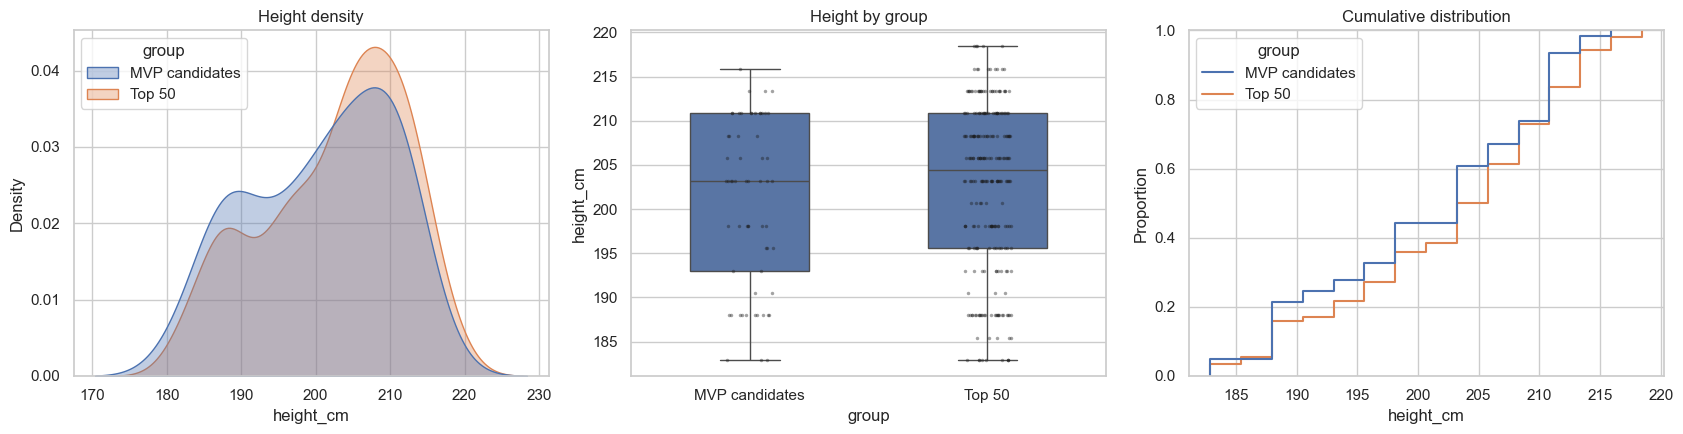

In [50]:
both = pd.concat([mvp_c.assign(group='MVP candidates'), top_all.assign(group='Top 50')], ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.kdeplot(data=both, x='height_cm', hue='group', common_norm=False, fill=True, alpha=.35, ax=axes[0])
axes[0].set_title('Height density')
sns.boxplot(data=both, x='group', y='height_cm', ax=axes[1], width=.5)
sns.stripplot(data=both, x='group', y='height_cm', ax=axes[1], color='k', size=2.5, alpha=.4)
axes[1].set_title('Height by group')
sns.ecdfplot(data=both, x='height_cm', hue='group', ax=axes[2])
axes[2].set_title('Cumulative distribution')
fig.tight_layout()
plt.show()

<div dir="rtl" style="text-align: right;">
<h4>آزمون‌های آماری</h4>
</div>

In [51]:
a, b = mvp_c.height_cm.dropna(), top_all.height_cm.dropna()
print('Shapiro MVP candidates p =', round(stats.shapiro(a).pvalue, 4))
print('Shapiro Top 50 p =', round(stats.shapiro(b).pvalue, 4))
print('Levene p =', round(stats.levene(a, b).pvalue, 4))
t = stats.ttest_ind(a, b, equal_var=False)
mwu = stats.mannwhitneyu(a, b, alternative='two-sided')
pooled = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
rng = np.random.default_rng(42)
boot = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(10000)]
print('Welch t =', round(t.statistic, 3), 'p =', round(t.pvalue, 4))
print('Mann-Whitney p =', round(mwu.pvalue, 4))
print("Cohen's d =", round((a.mean() - b.mean()) / pooled, 3))
print('Mean difference (cm) =', round(a.mean() - b.mean(), 2),
      '95% bootstrap CI =', np.percentile(boot, [2.5, 97.5]).round(2))

Shapiro MVP candidates p = 0.0006
Shapiro Top 50 p = 0.0
Levene p = 0.854


Welch t = -1.37 p = 0.1742
Mann-Whitney p = 0.18
Cohen's d = -0.196
Mean difference (cm) = -1.85 95% bootstrap CI = [-4.49  0.77]


<div dir="rtl" style="text-align: right;">
<p>نامزدهای MVP به‌طور میانگین ۱٫۹ سانتی‌متر کوتاه‌ترند (۲۰۰٫۷ در برابر ۲۰۲٫۶)، ولی این تفاوت کوچک است (d حدود ۰٫۲) و معنادار نیست (p حدود ۰٫۱۷). بازه ۹۵٪ بوت‌استرپ هم صفر را شامل می‌شود.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h4>بررسی پایداری: گروه‌های مستقل و بازیکنان یکتا</h4>
</div>

In [52]:
top_only = top_all.merge(mvp_c[['player_key', 'season']], on=['player_key', 'season'],
                       how='left', indicator=True).query("_merge == 'left_only'")
rows = []
for name, x, y in [('Top 50 without MVP candidates', mvp_c.height_cm.dropna(), top_only.height_cm.dropna()),
                   ('Unique players', mvp_c.drop_duplicates('player_key').height_cm.dropna(),
                    top_all.drop_duplicates('player_key').height_cm.dropna())]:
    rows.append({'comparison': name, 'n_mvp': len(x), 'n_other': len(y),
                 'diff_cm': x.mean() - y.mean(),
                 'welch_p': stats.ttest_ind(x, y, equal_var=False).pvalue,
                 'mannwhitney_p': stats.mannwhitneyu(x, y).pvalue})
pd.DataFrame(rows).set_index('comparison')

,n_mvp,n_other,diff_cm,welch_p,mannwhitney_p
comparison,,,,,
Top 50 without MVP candidates,61,192,-2.326,0.097,0.102
Unique players,29,106,-2.991,0.133,0.137


<div dir="rtl" style="text-align: right;">
<h4>ترکیب پست‌ها در دو گروه</h4>
</div>

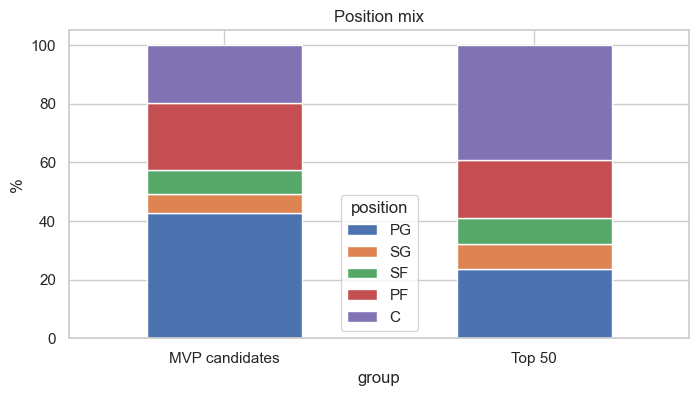

position           PG    SG    SF     PF      C
group                                          
MVP candidates 42.600 6.600 8.200 23.000 19.700
Top 50         23.600 8.400 9.200 19.600 39.200
Chi-square p = 0.0152


group,MVP candidates,Top 50
position,,
PG,193.900,191.600
SG,193.000,191.800
SF,200.200,200.400
PF,206.800,206.200
C,211.000,210.100


In [53]:
position_order = ['PG', 'SG', 'SF', 'PF', 'C']
pos = pd.crosstab(both.group, both.position)[position_order]
pos.div(pos.sum(axis=1), axis=0).mul(100).round(1).plot(kind='bar', stacked=True, figsize=(8, 4), rot=0)
plt.ylabel('%')
plt.title('Position mix')
plt.show()
print(pos.div(pos.sum(axis=1), axis=0).mul(100).round(1))
print('Chi-square p =', round(stats.chi2_contingency(pos)[1], 4))
both.groupby(['position', 'group']).height_cm.mean().unstack().loc[position_order].round(1)

<div dir="rtl" style="text-align: right;">
<p>ترکیب پست‌ها فرق دارد (p حدود ۰٫۰۱۵): ۴۳٪ نامزدها پوینت‌گارد هستند، ولی در ۵۰ نفر برتر فقط ۲۴٪. سنترها ۳۹٪ ۵۰ نفر برتر هستند. قد در هر پست در دو گروه تقریباً برابر است، پس اختلاف کوچک بالا از ترکیب پست‌ها می‌آید.</p>
</div>

<div dir="rtl" style="text-align: right;">
<h3 style="color:#d35400; border-right:5px solid #d35400; padding-right:10px;">6.2 سؤال ۲: تجربه و قد بازیکنان فعال تیم قهرمان در دو فصل آخر در برابر ۱۵ بازیکن برتر همان فصل</h3>
</div>

<div dir="rtl" style="text-align: right;">

قهرمان 2022-23 دنور است و قهرمان 2023-24 بوستون. «فعال» یعنی بازیکنی که برای تیم قهرمان حداقل ۲۰ بازی و هر بازی حداقل ۱۵ دقیقه بازی کرده، همان فیلتر سکشن ۴.۴؛ یعنی جزو چرخش اصلی تیم بوده، نه فقط اسمش در فهرست تیم آمده. ۱۵ بازیکن برتر از تابع سکشن ۵ می‌آیند. هر بازیکن در هر فصل یک ردیف است.

</div>

In [54]:
champion_query = '''
SELECT
    s.season_label AS season,
    t.team_name,
    p.player_key,
    p.player_name,
    c.experience_years,
    p.listed_height_inches,
    f.games_played,
    f.minutes_played
FROM fact_player_stats AS f
JOIN dim_season AS s ON s.season_key = f.season_key
JOIN dim_team_scope AS t ON t.scope_key = f.scope_key
JOIN dim_player AS p ON p.player_key = f.player_key
JOIN dim_player_context AS c ON c.context_key = f.context_key
WHERE f.phase_key = 1
  AND t.scope_code = s.champion_team_code
  AND s.season_label IN ('2022-23', '2023-24')
'''

with engine.connect() as connection:
    champion_players = pd.read_sql_query(text(champion_query), connection)

champion_players['height_cm'] = champion_players['listed_height_inches'] * 2.54
champion_players['minutes_per_game'] = champion_players['minutes_played'] / champion_players['games_played']
champion_players['is_active'] = (champion_players['games_played'] >= MIN_GAMES) & (champion_players['minutes_per_game'] >= MIN_MINUTES_PER_GAME)
active_champions = champion_players[champion_players['is_active']].copy()

print('champion players:', len(champion_players), '| active:', len(active_champions))
active_champions[['season', 'team_name', 'player_name', 'experience_years', 'height_cm', 'games_played']].round(1)

champion players: 37 | active: 19


,season,team_name,player_name,experience_years,height_cm,games_played
0,2022-23,Denver Nuggets,Aaron Gordon,8,203.200,68
1,2022-23,Denver Nuggets,Bones Hyland,1,188.000,42
2,2022-23,Denver Nuggets,Bruce Brown,4,193.000,80
3,2022-23,Denver Nuggets,Christian Braun,0,198.100,76
5,2022-23,Denver Nuggets,DeAndre Jordan,14,210.800,39
8,2022-23,Denver Nuggets,Jamal Murray,5,193.000,65
9,2022-23,Denver Nuggets,Jeff Green,14,203.200,56
10,2022-23,Denver Nuggets,Kentavious Caldwell-Pope,9,195.600,76
11,2022-23,Denver Nuggets,Michael Porter Jr.,3,208.300,62
12,2022-23,Denver Nuggets,Nikola Jokić,7,210.800,69


In [55]:
top15 = pd.concat([nba_top_players.get_top_players(engine, season, n=15) for season in ['2022-23', '2023-24']],
                  ignore_index=True)
top15 = top15.merge(player_stats[['player_key', 'season', 'experience_years', 'listed_height_inches']],
                    on=['player_key', 'season'], how='left')
top15['height_cm'] = top15['listed_height_inches'] * 2.54

in_both = top15.merge(active_champions[['player_key', 'season']], on=['player_key', 'season'])
print('top 15 rows:', len(top15), '| missing values:', top15[['experience_years', 'height_cm']].isna().sum().sum())
print('in both groups:', in_both['player_name'].tolist())

q2_groups = pd.concat([active_champions.assign(group='Champion actives'), top15.assign(group='Top 15')], ignore_index=True)
q2_groups.groupby('group')[['experience_years', 'height_cm']].agg(['count', 'mean', 'median', 'std']).round(2)

top 15 rows: 30 | missing values: 0
in both groups: ['Nikola Jokić', 'Jayson Tatum', 'Kristaps Porziņģis']


experience_years                    height_cm          \
                            count  mean median   std     count    mean   
group                                                                    
Champion actives               19 6.950  6.000 4.660        19 200.790   
Top 15                         30 7.730  7.000 3.230        30 203.200   

                                
                  median   std  
group                           
Champion actives 200.660 9.140  
Top 15           203.200 8.770

In [56]:
fig = px.box(q2_groups, x='group', y='experience_years', color='group', points='all', hover_name='player_name',
             facet_col='season', title='Experience: champion actives vs top 15',
             labels={'group': '', 'experience_years': 'Experience (seasons)'})
fig.show()

fig = px.box(q2_groups, x='group', y='height_cm', color='group', points='all', hover_name='player_name',
             facet_col='season', title='Height: champion actives vs top 15',
             labels={'group': '', 'height_cm': 'Height (cm)'})
fig.show()

<div dir="rtl" style="text-align: right;">

برای هر ویژگی فرض صفر این است که دو گروه فرقی ندارند (آزمون دوطرفه). اول Shapiro نرمال بودن هر دو گروه را چک می‌کند؛ اگر هر دو نرمال بودند، Levene بین t-test معمولی و Welch انتخاب می‌کند، وگرنه Mann-Whitney می‌زنیم. نمونه‌ها کوچک‌اند (حدود ۱۰ بازیکن فعال قهرمان در هر فصل)، پس دو فصل را با هم هم آزمون می‌کنیم. سه بازیکن در هر دو گروه هستند؛ برای اطمینان، آزمون را یک بار هم بدون آن‌ها تکرار می‌کنیم.

</div>

In [57]:
def compare_groups(a, b):
    a = pd.Series(a).dropna()
    b = pd.Series(b).dropna()
    if stats.shapiro(a).pvalue > 0.05 and stats.shapiro(b).pvalue > 0.05:
        equal_var = stats.levene(a, b).pvalue > 0.05
        test = 't-test' if equal_var else 'Welch t-test'
        p_value = stats.ttest_ind(a, b, equal_var=equal_var).pvalue
    else:
        test = 'Mann-Whitney'
        p_value = stats.mannwhitneyu(a, b).pvalue
    return {'test': test, 'n_a': len(a), 'n_b': len(b),
            'mean_a': round(float(a.mean()), 2), 'mean_b': round(float(b.mean()), 2),
            'median_a': float(a.median()), 'median_b': float(b.median()), 'p_value': round(float(p_value), 4)}


q2_rows = {}
for column in ['experience_years', 'height_cm']:
    q2_rows[column + ' (two seasons)'] = compare_groups(active_champions[column], top15[column])
    for season in ['2022-23', '2023-24']:
        q2_rows[f'{column} ({season})'] = compare_groups(
            active_champions.loc[active_champions['season'] == season, column],
            top15.loc[top15['season'] == season, column])

overlap_keys = set(zip(in_both['player_key'], in_both['season']))
top15_only = top15[[(k, s) not in overlap_keys for k, s in zip(top15['player_key'], top15['season'])]]
champions_only = active_champions[[(k, s) not in overlap_keys for k, s in zip(active_champions['player_key'], active_champions['season'])]]
for column in ['experience_years', 'height_cm']:
    q2_rows[column + ' (without overlap)'] = compare_groups(champions_only[column], top15_only[column])

pd.DataFrame(q2_rows).T

,test,n_a,n_b,mean_a,mean_b,median_a,median_b,p_value
experience_years (two seasons),t-test,19,30,6.950,7.730,6.000,7.000,0.488
experience_years (2022-23),t-test,10,15,6.500,7.930,6.000,7.000,0.416
experience_years (2023-24),t-test,9,15,7.440,7.530,6.000,7.000,0.953
height_cm (two seasons),t-test,19,30,200.790,203.200,200.660,203.200,0.362
height_cm (2022-23),t-test,10,15,200.410,201.340,200.660,203.200,0.795
height_cm (2023-24),t-test,9,15,201.220,205.060,200.660,205.740,0.338
experience_years (without overlap),t-test,16,27,7.000,7.850,6.000,7.000,0.513
height_cm (without overlap),t-test,16,27,198.910,202.350,198.120,203.200,0.206


<div dir="rtl" style="text-align: right;">

اگر به‌جای بازیکنان فعال کل فهرست تیم قهرمان را بگیریم چه؟

</div>

In [58]:
pd.DataFrame({
    'experience_years (whole roster)': compare_groups(champion_players['experience_years'], top15['experience_years']),
    'height_cm (whole roster)': compare_groups(champion_players['height_cm'], top15['height_cm']),
}).T

,test,n_a,n_b,mean_a,mean_b,median_a,median_b,p_value
experience_years (whole roster),Mann-Whitney,37,30,5.140,7.730,4.000,7.000,0.003
height_cm (whole roster),t-test,37,30,200.110,203.200,200.660,203.200,0.148


<div dir="rtl" style="text-align: right;">

#### جواب سؤال ۲

۱۹ بازیکن فعال قهرمان (۱۰ نفر از دنور و ۹ نفر از بوستون) را با ۳۰ ردیف ۱۵ نفر برتر مقایسه کردیم. بازیکنان فعال قهرمان کمی کم‌تجربه‌ترند (میانگین ۶.۹ سال در برابر ۷.۷) و کمی کوتاه‌ترند (۲۰۰.۸ در برابر ۲۰۳.۲ سانتی‌متر)، اما هیچ‌کدام از این فرق‌ها معنادار نیست. برای تجربه p برابر ۰.۴۹ و برای قد ۰.۳۶ است، چه دو فصل را با هم آزمون کنیم، چه هر فصل را جدا، و چه بدون سه بازیکنی که در هر دو گروه‌اند (یوکیچ، تیتوم و پورزینگیس). پس بازیکنانی که واقعاً برای تیم قهرمان بازی کرده‌اند، از نظر تجربه و قد شبیه ستاره‌های لیگ‌اند.

اما اگر کل فهرست تیم قهرمان را حساب کنیم، ۱۵ نفر برتر **به‌طور معنادار باتجربه‌ترند** (میانه‌ی ۷ سال در برابر ۴، Mann-Whitney p = 0.003)؛ قد هنوز فرقی ندارد (p = 0.15). دلیلش بازیکن‌های جوان نیمکت است که در فهرست تیم هستند ولی کم بازی می‌کنند. برای همین تعریف «بازیکن فعال» نتیجه را عوض می‌کند و ما تعریف چرخش اصلی تیم را ملاک گرفتیم. نمونه‌ها کوچک‌اند (۹ و ۱۰ بازیکن در هر فصل)، پس این نتیجه را با احتیاط بخوانید.

</div>

<div dir="rtl" style="text-align: right;">
<h3 style="color:#d35400; border-right:5px solid #d35400; padding-right:10px;">6.3 سؤال ۳: خرید پوینت‌گارد بر اساس حضور در لیست Michael Jordan Trophy</h3>
</div>

<div dir="rtl" style="text-align: right;">

باشگاهی برای فصل بعد پوینت گارد می خواهد. معیار توانایی، حضور در لیست <span dir="ltr">Michael Jordan Trophy</span> (لیست رأی <span dir="ltr">MVP</span>) است و حضور بیشتر اولویت بالاتر دارد. با آمار 2019-20 تا 2023-24 باید لیست بازیکن های مناسب را بسازیم و سه پیشنهاد بدهی


#### خواندن رأی ها


</div>

In [59]:
votes_query = '''
SELECT
    p.player_key,
    p.player_name,
    s.season_label AS season,
    c.position_code AS position,
    m.voting_points_won,
    s.maximum_mvp_voting_points
FROM fact_mvp_voting AS m
JOIN dim_player AS p ON p.player_key = m.player_key
JOIN dim_season AS s ON s.season_key = m.season_key
JOIN dim_player_context AS c ON c.context_key = m.context_key
'''

with engine.connect() as connection:
    votes = pd.read_sql_query(text(votes_query), connection)

print(votes.shape, '| duplicates:', votes.duplicated(['player_key', 'season']).sum(), '| nulls:', votes.isna().sum().sum())
votes.head()

(61, 6) | duplicates: 0 | nulls: 0


,player_key,player_name,season,position,voting_points_won,maximum_mvp_voting_points
0,47,Anthony Davis,2019-20,PF,82,1010
1,142,Chris Paul,2019-20,PG,26,1010
2,176,Damian Lillard,2019-20,PG,23,1010
3,313,Giannis Antetokounmpo,2019-20,PF,962,1010
4,410,James Harden,2019-20,SG,367,1010


<div dir="rtl" style="text-align: right;">

تکراری و خالی نداریم. سقف امتیاز رأی هر فصل فرق دارد

برای همین سهم رأی می سازیم (امتیاز بازیکن تقسیم بر بیشترین امتیاز ممکن آن فصل) و رتبه ی هر بازیکن را در فصلش حساب می کنیم

</div>

In [60]:
votes['vote_share'] = votes['voting_points_won'] / votes['maximum_mvp_voting_points']
votes['vote_rank'] = votes.groupby('season')['voting_points_won'].rank(ascending=False, method='min').astype(int)

print('skew:', round(votes['vote_share'].skew(), 2))
votes['vote_share'].describe().round(3)

skew: 1.34


count   61.000
mean     0.213
std      0.306
min      0.001
25%      0.004
50%      0.030
75%      0.345
max      0.961
Name: vote_share, dtype: float64

In [61]:
histogram_with_box(votes['vote_share'], 'MVP vote share', 'Vote share', bins=20).show()

<div dir="rtl" style="text-align: right;">

سهم رأی خیلی چوله است. هر فصل یکی دو نفر بیشتر رأی ها را می برند و بقیه سهم کمی دارند. پس میانگین سهم رأی گمراه کننده است و معیار اصلی ما تعداد فصل های حضور می شود

#### پست بازیکن

پست یک بازیکن ممکن است از فصلی به فصل دیگر عوض شود. پست آخرین فصل را ملاک می گیریم

</div>

In [62]:
latest = player_stats.sort_values('season').groupby('player_key').tail(1)
latest = latest[['player_key', 'season', 'position', 'age', 'games_played', 'points', 'assists',
                 'win_shares', 'box_plus_minus', 'annual_salary_usd']]
latest = latest.rename(columns={'season': 'last_season', 'position': 'last_position', 'age': 'last_age'})

voted_players = votes.merge(latest, on='player_key')
changed = voted_players[voted_players['position'] != voted_players['last_position']]
changed[['player_name', 'season', 'position', 'last_position']].drop_duplicates('player_name')

,player_name,season,position,last_position
0,Anthony Davis,2019-20,PF,C
4,James Harden,2019-20,SG,PG
6,Jimmy Butler,2019-20,SF,PF
8,LeBron James,2019-20,PG,PF
28,DeMar DeRozan,2021-22,PF,SF
29,Devin Booker,2021-22,SG,PG
32,Jayson Tatum,2021-22,SF,PF


<div dir="rtl" style="text-align: right;">

#### رتبه بندی پوینت گاردها

کاندیدا کسی است که پستش در آخرین فصل <span dir="ltr">PG</span> باشد و حداقل یک بار در لیست <span dir="ltr">MVP</span> آمده باشد

</div>

In [63]:
pg_votes = voted_players[voted_players['last_position'] == 'PG']

ranking = pg_votes.groupby(['player_key', 'player_name']).agg(
    appearances=('season', 'count'),
    total_vote_share=('vote_share', 'sum'),
    best_rank=('vote_rank', 'min'),
    last_season=('last_season', 'first'),
    last_age=('last_age', 'first'),
    last_games=('games_played', 'first'),
    last_points=('points', 'first'),
    last_assists=('assists', 'first'),
    last_win_shares=('win_shares', 'first'),
    last_bpm=('box_plus_minus', 'first'),
    last_salary=('annual_salary_usd', 'first'),
).reset_index()

ranking['age_next_season'] = ranking['last_age'] + 1
ranking['points_per_game'] = ranking['last_points'] / ranking['last_games']
ranking['assists_per_game'] = ranking['last_assists'] / ranking['last_games']
ranking['salary_million'] = ranking['last_salary'] / 1_000_000
ranking['ws_per_million'] = ranking['last_win_shares'] / ranking['salary_million']

ranking = ranking.sort_values(['appearances', 'total_vote_share'], ascending=False).reset_index(drop=True)
ranking.index = ranking.index + 1
ranking[['player_name', 'appearances', 'total_vote_share', 'best_rank', 'age_next_season',
         'points_per_game', 'assists_per_game', 'last_win_shares', 'last_bpm', 'salary_million',
         'ws_per_million']].round(3)

,player_name,appearances,total_vote_share,best_rank,age_next_season,points_per_game,assists_per_game,last_win_shares,last_bpm,salary_million,ws_per_million
1,Luka Dončić,5,0.967,3,25,33.857,9.800,12.000,9.900,40.064,0.300
2,Stephen Curry,3,0.458,3,36,26.432,5.122,7.200,5.200,51.916,0.139
3,Chris Paul,3,0.165,5,39,9.190,6.776,4.300,1.000,30.800,0.140
4,Shai Gilgeous-Alexander,2,0.692,2,26,30.053,6.200,14.600,9.000,33.387,0.437
5,James Harden,2,0.364,3,35,16.556,8.528,8.400,4.100,35.681,0.235
6,Jalen Brunson,2,0.144,5,28,28.727,6.740,11.200,5.800,26.347,0.425
7,Damian Lillard,2,0.060,7,34,24.315,6.959,7.700,2.100,45.640,0.169
8,Ja Morant,2,0.011,7,25,25.111,8.111,0.800,3.100,34.005,0.024
9,Devin Booker,1,0.216,4,28,27.074,6.941,9.200,3.000,36.016,0.255
10,Derrick Rose,1,0.010,9,36,7.958,3.250,0.400,-2.800,3.196,0.125


<div dir="rtl" style="text-align: right;">

13 کاندیدا داریم. دونچیچ با 5 حضور اول است، کری و کریس پال هر کدام 3 حضور دارند، پنج نفر 2 حضور و پنج نفر دیگر فقط 1 حضور

</div>

In [64]:
fig = px.bar(ranking, x='player_name', y='appearances', color='total_vote_share', color_continuous_scale='Oranges',
             title='Point guards on the MVP list', labels={'player_name': '', 'appearances': 'Seasons on the list'})
fig.show()

top_names = ranking['player_name'].head(6)
fig = px.line(pg_votes[pg_votes['player_name'].isin(top_names)].sort_values('season'),
              x='season', y='vote_share', color='player_name', markers=True, title='Vote share of the top six')
fig.show()

<div dir="rtl" style="text-align: right;">

#### مقایسه با معیار بازیکن برتر تیم

 کسی که هم در لیست <span dir="ltr">MVP</span> زیاد آمده و هم در لیست برترها انتخاب مطمئن و احتمالی ما است

</div>

In [65]:
seasons = sorted(player_stats['season'].unique())
top_lists = pd.concat([nba_top_players.get_top_players(engine, season) for season in seasons], ignore_index=True)
top_counts = top_lists.groupby('player_key').size()

ranking['top50_seasons'] = ranking['player_key'].map(top_counts).fillna(0).astype(int)
ranking[['player_name', 'appearances', 'top50_seasons']]

,player_name,appearances,top50_seasons
1,Luka Dončić,5,5
2,Stephen Curry,3,4
3,Chris Paul,3,4
4,Shai Gilgeous-Alexander,2,2
5,James Harden,2,5
6,Jalen Brunson,2,3
7,Damian Lillard,2,4
8,Ja Morant,2,2
9,Devin Booker,1,4
10,Derrick Rose,1,0


<div dir="rtl" style="text-align: right;">

#### آیا لیست <span dir="ltr">MVP</span> معیار خوبی است؟

</div>

In [66]:
pg_seasons = df[df['position'] == 'PG'].copy()
voted_keys = set(zip(votes['player_key'], votes['season']))
pg_seasons['on_mvp_list'] = [(k, s) in voted_keys for k, s in zip(pg_seasons['player_key'], pg_seasons['season'])]

mvp_group = pg_seasons.loc[pg_seasons['on_mvp_list'], 'win_shares']
other_group = pg_seasons.loc[~pg_seasons['on_mvp_list'], 'win_shares']

both_normal = stats.shapiro(mvp_group).pvalue > ALPHA and stats.shapiro(other_group).pvalue > ALPHA
if both_normal:
    test_name = 't-test (Welch)'
    p_value = stats.ttest_ind(mvp_group, other_group, equal_var=False, alternative='greater').pvalue
else:
    test_name = 'Mann-Whitney'
    p_value = stats.mannwhitneyu(mvp_group, other_group, alternative='greater').pvalue

print(test_name, '| p =', p_value)
print('MVP list:', len(mvp_group), 'seasons, median WS', round(mvp_group.median(), 1))
print('others:', len(other_group), 'seasons, median WS', round(other_group.median(), 1))

Mann-Whitney | p = 3.583706198207455e-14
MVP list: 26 seasons, median WS 8.8
others: 291 seasons, median WS 2.5


In [67]:
pg_seasons['group'] = np.where(pg_seasons['on_mvp_list'], 'MVP list', 'other seasons')
fig = px.box(pg_seasons, x='group', y='win_shares', color='group', points='outliers',
             title='Win shares of point guards', labels={'group': ''})
fig.show()

voted_seasons = votes.merge(player_stats[['player_key', 'season', 'win_shares']], on=['player_key', 'season'])
rho, p_rho = stats.spearmanr(voted_seasons['vote_share'], voted_seasons['win_shares'])
print('vote share vs win shares: rho =', round(rho, 2), ', p =', p_rho)

vote share vs win shares: rho = 0.62 , p = 9.406543068380755e-08


<div dir="rtl" style="text-align: right;">

نتیجه ی آزمون:

<span dir="ltr">p</span> خیلی کوچک است و فرض صفر رد می شود

<span dir="ltr">Win Shares</span> فصل های لیست <span dir="ltr">MVP</span> (26 فصل، میانه ی 8.8) واقعاً از بقیه ی فصل ها (291 فصل، میانه ی 2.5) بیشتر است. همبستگی سهم رأی و <span dir="ltr">Win Shares</span> هم 0.62 شد.

</div>

<div dir="rtl" style="text-align: right;">

#### سن و هزینه

بازیکن عالی که فصل بعد 39 ساله است یا نصف بودجه ی تیم را می خواهد انتخاب خوبی نیست

</div>

In [68]:
fig = px.scatter(ranking, x='age_next_season', y='total_vote_share', size='appearances', color='salary_million',
                 text='player_name', size_max=40, color_continuous_scale='Viridis',
                 title='Candidates: age, vote share, appearances, salary',
                 labels={'age_next_season': 'Age next season', 'total_vote_share': 'Total vote share',
                         'salary_million': 'Salary ($M)'})
fig.update_traces(textposition='top center')
fig.show()

<div dir="rtl" style="text-align: right;">

#### جمع بندی و سه پیشنهاد

اول خود معیار را چک کردیم. فصل هایی که پوینت گاردها در لیست <span dir="ltr">MVP</span> بوده اند میانه ی <span dir="ltr">Win Shares</span> برابر 8.8 دارند و بقیه 2.5 (<span dir="ltr">Mann-Whitney</span>، <span dir="ltr">p</span> < 0.001). سهم رأی هم با <span dir="ltr">Win Shares</span> همبستگی 0.62 دارد. پس معیار قابل اعتماد است. معیار بازیکن برتر تیم هم همین را نشان می دهد: دونچیچ در هر پنج فصل جزو 50 نفر برتر بوده، کری در 4 فصل و برانسون در 3 فصل. گیلجس-الکساندر فقط در دو فصل آخر (رتبه 4 در 2022-23 و رتبه 2 در 2023-24) جزو آنها بوده، همان دو فصلی که در لیست <span dir="ltr">MVP</span> هم بود، چون دیر به اوج رسید.

طبق معیار سؤال سه نفر اول دونچیچ (5 حضور)، کری (3) و کریس پال (3) هستند. پال فصل بعد 39 ساله است و آخرین فصلش فقط 9.2 امتیاز و <span dir="ltr">BPM</span> برابر 1.0 داشته. برای خرید فصل بعد ریسک زیادی دارد و کنارش می گذاریم.

پیشنهادها:

1. لوکا دونچیچ. هر پنج فصل در لیست <span dir="ltr">MVP</span>، بیشترین مجموع سهم رأی (0.97)، فصل بعد 25 ساله، با 33.9 امتیاز و 9.8 پاس در هر بازی و حقوق 40.1 میلیون دلار.
2. شای گیلجس-الکساندر. فقط دو حضور ولی نفر دوم <span dir="ltr">MVP</span> در 2023-24 و بیشترین <span dir="ltr">Win Shares</span> بین کاندیدها (14.6). 26 ساله با 33.4 میلیون دلار، و به ازای هر میلیون دلار 0.44 <span dir="ltr">Win Share</span> می دهد (دونچیچ 0.30).
3. استفن کری. سه حضور و 26.4 امتیاز در هر بازی، ولی 36 ساله و گران ترین کاندیدا (51.9 میلیون دلار). فقط برای قرارداد کوتاه.

اگر بودجه کم باشد جیلن برانسون جایگزین خوبی است: دو حضور، 28 ساله و 26.3 میلیون دلار، با 0.43 <span dir="ltr">Win Share</span> به ازای هر میلیون دلار.

</div>

<div dir="rtl" style="text-align: right;">
<h2 style="background:#c0392b; color:white; padding:8px 14px; border-radius:8px;">7. آزمون فرض</h2>
<h3 style="color:#c0392b; border-right:5px solid #c0392b; padding-right:10px;">7.1 فرضیه ۱: میانگین چابکی (قد تقسیم بر وزن) ۲۰ بازیکن برتر در فصل‌های 2022-23 و 2023-24 بیشتر از 2020-21 و 2021-22 است</h3>
</div>

<div dir="rtl" style="direction: rtl; text-align: right; line-height: 2;">

<h4 dir="rtl" style="direction: rtl; text-align: right;">
تعریف مسئله
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
در این بخش بررسی می‌کنیم آیا میانگین شاخص چابکیِ ۲۰ بازیکن برتر هر فصل، در دورهٔ جدید نسبت به دورهٔ قدیم افزایش یافته است یا خیر. مطابق تعریف صورت پروژه، شاخص چابکی از تقسیم قد بازیکن بر وزن او محاسبه می‌شود.
</p>

<h4 dir="rtl" style="direction: rtl; text-align: right;">
دوره‌های مقایسه
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
<strong>دورهٔ قدیم:</strong>
فصل‌های
<span dir="ltr" style="direction: ltr; unicode-bidi: isolate; display: inline-block; white-space: nowrap;">2020-21</span>
و
<span dir="ltr" style="direction: ltr; unicode-bidi: isolate; display: inline-block; white-space: nowrap;">2021-22</span>.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
<strong>دورهٔ جدید:</strong>
فصل‌های
<span dir="ltr" style="direction: ltr; unicode-bidi: isolate; display: inline-block; white-space: nowrap;">2022-23</span>
و
<span dir="ltr" style="direction: ltr; unicode-bidi: isolate; display: inline-block; white-space: nowrap;">2023-24</span>.
</p>

<h4 dir="rtl" style="direction: rtl; text-align: right;">
معیار انتخاب بازیکنان
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
برای یکسان‌بودن معیار انتخاب در بخش‌های مختلف پروژه، از تابع مشترک تیم با نام
<span dir="ltr" style="direction: ltr; unicode-bidi: isolate; display: inline-block; white-space: nowrap;"><code>get_top_players</code></span>
استفاده می‌کنیم. برای هر فصل، ۲۰ بازیکن نخست بر اساس امتیاز ترکیبی این تابع انتخاب می‌شوند. این تابع، آمار فصل عادی و حداقل ۱۰۰۰ دقیقه بازی را مبنا قرار می‌دهد و برای بازیکنان چندتیمی از آمار تجمیعی فصل استفاده می‌کند.
</p>

<h4 dir="rtl" style="direction: rtl; text-align: right;">
تعریف شاخص و واحد مشاهده
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
شاخص چابکی را با استفاده از واحدهای موجود در دیتابیس،
از تقسیم قد برحسب اینچ بر وزن برحسب پوند محاسبه می‌کنیم.
واحدها برای تمام بازیکنان و فصل‌ها یکسان نگه داشته می‌شوند.
سپس میانگین نسبت‌های فردی را در دو دوره مقایسه می‌کنیم.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
واحد مشاهده، «بازیکن در یک فصل» است. بنابراین انتظار داریم در هر فصل ۲۰ رکورد و در هر دوره ۴۰ رکورد داشته باشیم.
</p>

<h4 dir="rtl" style="direction: rtl; text-align: right;">
فرضیه‌های آماری
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
<strong>فرض صفر:</strong>
میانگین شاخص در دورهٔ جدید، کمتر یا مساوی دورهٔ قدیم است.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
<strong>فرض مقابل:</strong>
میانگین شاخص در دورهٔ جدید، بیشتر از دورهٔ قدیم است.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
سطح معناداری را پیش از اجرای آزمون برابر با ۰٫۰۵ در نظر می‌گیریم.
</p>

</div>

In [69]:
top_2020_21 = nba_top_players.get_top_players(db=engine, season="2020-21", n=20)

top_2021_22 = nba_top_players.get_top_players(db=engine, season="2021-22", n=20)

top_2022_23 = nba_top_players.get_top_players(db=engine, season="2022-23", n=20)

top_2023_24 = nba_top_players.get_top_players(db=engine, season="2023-24", n=20)

all_top_players = pd.concat(
    [top_2020_21, top_2021_22, top_2022_23, top_2023_24],
    ignore_index=True,
)

print(f"Shape of DF : {all_top_players.shape}\n",
      f"Value Counts based on season : \n{all_top_players.value_counts(subset='season')}\n",
      f"Duplicate counts based on season and player key:{all_top_players.duplicated(subset=['player_key', 'season']).sum()}\n")

Shape of DF : (80, 15)
 Value Counts based on season : 
season
2020-21    20
2021-22    20
2022-23    20
2023-24    20
Name: count, dtype: int64
 Duplicate counts based on season and player key:0



In [70]:
top_query = text("""
    SELECT player_key, listed_height_inches, listed_weight_pounds
    FROM dim_player
    WHERE player_key IN :player_keys
""")
top_query = top_query.bindparams(
    bindparam("player_keys", expanding=True)
)

with engine.connect() as connection:
    player_measurements = pd.read_sql_query(
        top_query,
        connection,
        params={"player_keys": all_top_players["player_key"].unique().tolist()},
    )

print(
    f"{len(all_top_players['player_key'].unique())}\n",
    f"{len(player_measurements)}\n",
    f"{player_measurements.isna().sum()}\n",
    f"{player_measurements.duplicated(subset='player_key').sum()}\n"
)

41
 41
 player_key              0
listed_height_inches    0
listed_weight_pounds    0
dtype: int64
 0



In [71]:
merged_top_df = pd.merge(
    all_top_players,
    player_measurements,
    on="player_key",
    how="left",
    validate="many_to_one",
)

print(
    f"{merged_top_df.shape}\n",
    f"{merged_top_df.isna().sum()}\n",
    f"{merged_top_df.duplicated(subset=['player_key', 'season']).sum()}\n"
    f"{((merged_top_df['listed_height_inches'] > 0) & (merged_top_df['listed_weight_pounds'] > 0)).all()}\n"
)

merged_top_df["agility_ratio"] = merged_top_df["listed_height_inches"] / merged_top_df["listed_weight_pounds"]

season_map = {
    "2020-21": "old",
    "2021-22": "old",
    "2022-23": "new",
    "2023-24": "new",
}

merged_top_df["period"] = merged_top_df["season"].map(season_map)

(80, 17)
 rank                         0
player_key                   0
player_name                  0
season                       0
team                         0
position                     0
games_played                 0
minutes_played               0
box_plus_minus               0
player_efficiency_rating     0
win_shares_per_48_minutes    0
win_shares                   0
impact_z                     0
volume_z                     0
score                        0
listed_height_inches         0
listed_weight_pounds         0
dtype: int64
 0
True



In [72]:
period_summary = merged_top_df.groupby("period")["agility_ratio"].describe()

season_summary = merged_top_df.groupby("season")["agility_ratio"].describe()

display(period_summary)
display(season_summary)

,count,mean,std,min,25%,50%,75%,max
period,,,,,,,,
new,40.000,0.352,0.032,0.292,0.332,0.346,0.376,0.416
old,40.000,0.345,0.036,0.275,0.325,0.339,0.358,0.451


,count,mean,std,min,25%,50%,75%,max
season,,,,,,,,
2020-21,20.000,0.337,0.031,0.275,0.319,0.333,0.348,0.411
2021-22,20.000,0.353,0.039,0.292,0.329,0.342,0.371,0.451
2022-23,20.000,0.354,0.030,0.292,0.338,0.347,0.373,0.416
2023-24,20.000,0.350,0.035,0.292,0.328,0.340,0.376,0.416


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 2;">

<h4 dir="rtl" style="direction: rtl; text-align: right;">
برداشت اولیه از آمار توصیفی
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
هر دوره شامل ۴۰ رکورد بازیکن‌ـ‌فصل است.
میانگین شاخص قد به وزن در دورهٔ جدید حدود ۰٫۳۵۲
و در دورهٔ قدیم حدود ۰٫۳۴۵ است.
میانه نیز از حدود ۰٫۳۳۹ در دورهٔ قدیم
به ۰٫۳۴۶ در دورهٔ جدید افزایش یافته است.
بنابراین، هر دو معیار مرکزی در دورهٔ جدید مقدار بیشتری دارند.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
بررسی جداگانهٔ فصل‌ها نشان می‌دهد میانگین شاخص
در سه فصل نخست افزایش یافته، اما در فصل آخر کاهش پیدا کرده است.
در نتیجه، بالاتربودن میانگین دورهٔ جدید
به معنای افزایش پیوستهٔ شاخص در تمام فصل‌ها نیست.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
این نتایج، توصیف تفاوت مشاهده‌شده در داده‌ها هستند
و به‌تنهایی برای نتیجه‌گیری دربارهٔ معناداری آماری
یا تعمیم آن به فصل‌های دیگر کافی نیستند.
اعداد این بخش به‌صورت تقریبی گزارش شده‌اند.
</p>

</div>

In [73]:
player_season_mean_difference = (
    period_summary.loc["new", "mean"]
    - period_summary.loc["old", "mean"]
)

player_season_percentage_change = (
    player_season_mean_difference
    / period_summary.loc["old", "mean"]
) * 100

print(
    player_season_mean_difference,
    player_season_percentage_change,
)

0.006962399718235424 2.018811057800789


In [74]:
fig_box = px.box(merged_top_df, x="period", y="agility_ratio")
fig_box.update_traces(boxmean=True)
fig_box.show()

In [75]:
player_season_count_distribution = merged_top_df.groupby("player_key")["season"].nunique().value_counts()

unique_players_per_period = merged_top_df.groupby("period")["player_key"].nunique()

player_period_count_distribution = merged_top_df.groupby("player_key")["period"].nunique().value_counts()

display(
    player_season_count_distribution
    .rename_axis("season_count")
    .to_frame(name="player_count")
)

display(
    unique_players_per_period
    .to_frame(name="unique_players")
)

display(
    player_period_count_distribution
    .rename_axis("period_count")
    .to_frame(name="player_count")
)

,player_count
season_count,
1,19
2,10
3,7
4,5


,unique_players
period,
new,26
old,29


,player_count
period_count,
1,27
2,14


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 2;">

<h4 dir="rtl" style="direction: rtl; text-align: right;">
ساختار مشاهدات و آماده‌سازی برای آزمون
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
۸۰ مشاهدهٔ بازیکن‌ـ‌فصل، متعلق به ۴۱ بازیکن متفاوت است.
دورهٔ قدیم ۲۹ بازیکن متفاوت و دورهٔ جدید ۲۶ بازیکن متفاوت دارد.
از این میان، ۱۴ بازیکن در هر دو دوره حضور دارند.
بنابراین، دو گروه نه کاملاً مستقل و نه کاملاً زوجی هستند.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
برای بررسی تکمیلی با آزمون نمونه‌های دارای هم‌پوشانی جزئی،
برای هر بازیکن در هر دوره فقط یک مقدار در نظر می‌گیریم.
این مقدار از میانگین شاخص او در فصل‌های منتخب همان دوره به دست می‌آید.
در این تحلیل، هر بازیکن در هر دوره وزن برابر دارد؛
در حالی که در تحلیل توصیفی قبلی، هر حضور فصلی یک سهم داشت.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
قد و وزن ثبت‌شده برای هر بازیکن در دیتابیس ثابت است.
بنابراین، مقایسهٔ حاضر تفاوت ترکیب بازیکنان منتخب را بررسی می‌کند
و نشان‌دهندهٔ تغییر بدنی همان بازیکنان در طول زمان نیست.
</p>

</div>

In [76]:
player_period = (
    merged_top_df
    .groupby(["player_key", "period"])["agility_ratio"]
    .mean()
    .unstack("period")
    .reindex(columns=["old", "new"])
)

paired = player_period.dropna(subset=["old", "new"])

new_only = player_period.loc[
    player_period["old"].isna(), "new"
].to_numpy()

old_only = player_period.loc[
    player_period["new"].isna(), "old"
].to_numpy()

paired_new = paired["new"].to_numpy()
paired_old = paired["old"].to_numpy()

distinct_player_summary = player_period.describe().T

distinct_player_mean_difference = distinct_player_summary.loc["new", "mean"] - distinct_player_summary.loc["old", "mean"]
distinct_player_percentage_change = (distinct_player_mean_difference / distinct_player_summary.loc["old", "mean"]) * 100

display(distinct_player_summary)

print(
    f"Mean difference: {distinct_player_mean_difference:.6f}\n"
    f"Percentage change: {distinct_player_percentage_change:.2f}%"
)

,count,mean,std,min,25%,50%,75%,max
period,,,,,,,,
old,29.000,0.347,0.038,0.275,0.325,0.339,0.370,0.451
new,26.000,0.352,0.031,0.292,0.332,0.346,0.373,0.416


Mean difference: 0.005331
Percentage change: 1.54%


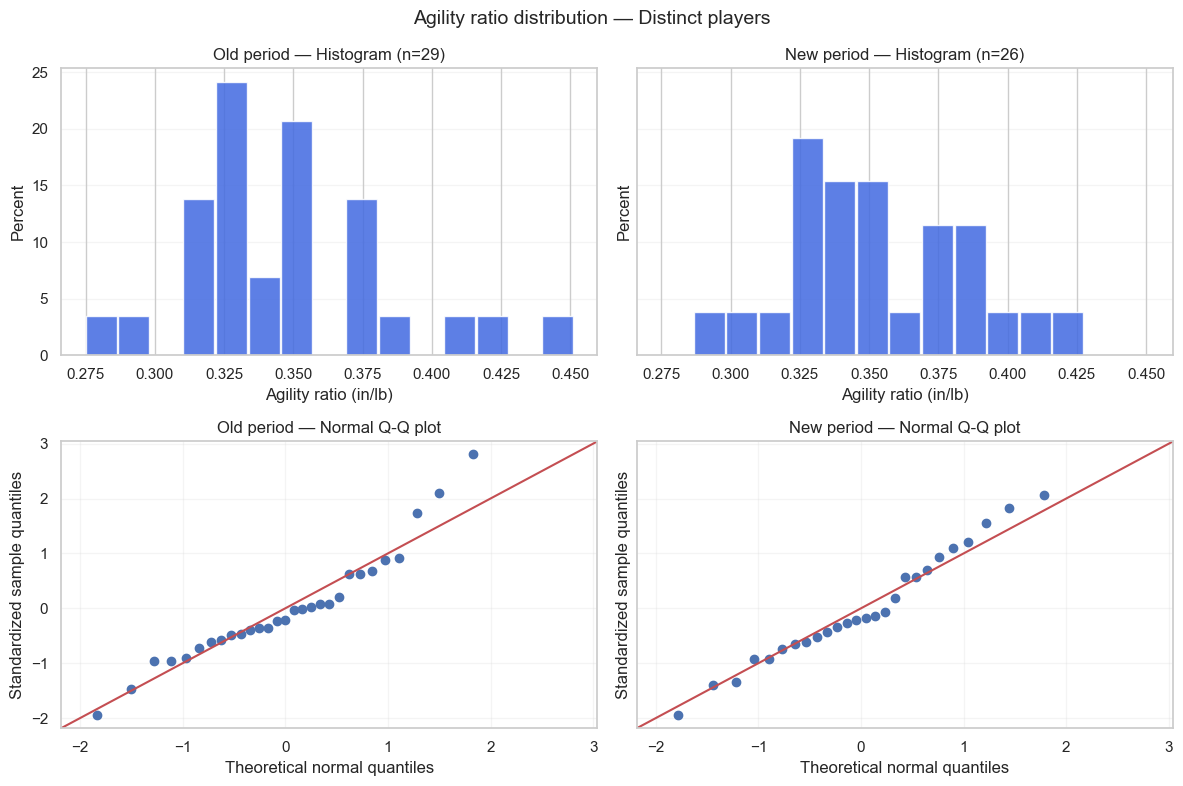

In [77]:
old_values = player_period["old"].dropna().to_numpy()
new_values = player_period["new"].dropna().to_numpy()

# Use identical bin boundaries for both periods.
all_values = np.concatenate([old_values, new_values])
bin_edges = np.histogram_bin_edges(all_values, bins=15)

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 8),
    sharex="row",
    sharey="row",
)

period_data = [
    ("Old", old_values),
    ("New", new_values),
]

for column, (period_name, values) in enumerate(period_data):
    # Each observation contributes an equal percentage within its period.
    weights = np.full(len(values), 100.0 / len(values))

    axes[0, column].hist(
        values,
        bins=bin_edges,
        weights=weights,
        color="royalblue",
        edgecolor="white",
        alpha=0.85,
        rwidth=0.95,
    )

    axes[0, column].set_title(
        f"{period_name} period — Histogram (n={len(values)})"
    )
    axes[0, column].set_xlabel("Agility ratio (in/lb)")
    axes[0, column].set_ylabel("Percent")
    axes[0, column].grid(axis="y", alpha=0.2)
    axes[0, column].set_axisbelow(True)

    sm.qqplot(
        values,
        fit=True,
        line="45",
        ax=axes[1, column],
    )

    axes[1, column].set_title(
        f"{period_name} period — Normal Q-Q plot"
    )
    axes[1, column].set_xlabel("Theoretical normal quantiles")
    axes[1, column].set_ylabel("Standardized sample quantiles")
    axes[1, column].grid(alpha=0.2)
    axes[1, column].set_axisbelow(True)

fig.suptitle(
    "Agility ratio distribution — Distinct players",
    fontsize=14,
)

plt.tight_layout()
plt.show()

In [78]:
shapiro_old_w, shapiro_old_p = stats.shapiro(
    old_values
)

shapiro_new_w, shapiro_new_p = stats.shapiro(
    new_values
)

normality_summary = pd.DataFrame({
    "period": ["old", "new"],
    "n": [
        player_period["old"].count(),
        player_period["new"].count(),
    ],
    "W": [shapiro_old_w, shapiro_new_w],
    "p_value": [shapiro_old_p, shapiro_new_p],
}).set_index("period")

display(normality_summary)

,n,W,p_value
period,,,
old,29,0.941,0.108
new,26,0.973,0.712


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 2;">

<h4 dir="rtl" style="direction: rtl; text-align: right;">
بررسی شکل توزیع شاخص
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
بررسی توزیع در این بخش بر اساس بازیکنان متفاوت هر دوره انجام شد؛
یعنی ۲۹ مقدار برای دورهٔ قدیم و ۲۶ مقدار برای دورهٔ جدید.
هیستوگرام‌ها تمرکز اصلی مقادیر دو دوره را در محدوده‌های نزدیک
و دنبالهٔ راست بلندتر دورهٔ قدیم را نشان می‌دهند.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
در نمودارهای چندک‌ـ‌چندک، بخش زیادی از نقاط خط مرجع نرمال را
تقریباً دنبال می‌کنند؛ بااین‌حال، در مقادیر بالای دورهٔ قدیم
فاصلهٔ بیشتری از خط دیده می‌شود.
بنابراین، سازگاری با توزیع نرمال کامل نیست
و انحراف انتهای بالایی باید در تفسیر لحاظ شود.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
در آزمون شاپیروـ‌ویلک، فرض صفر نرمال‌بودن توزیع است.
مقدار احتمال برای دورهٔ قدیم حدود ۰٫۱۰۸
و برای دورهٔ جدید حدود ۰٫۷۱۲ به دست آمد.
هر دو مقدار از سطح معناداری ۰٫۰۵ بیشترند؛
بنابراین، شواهد کافی برای رد نرمال‌بودن هیچ‌یک از دو گروه نداریم.
این نتیجه به معنی اثبات نرمال‌بودن نیست،
به‌ویژه با توجه به تعداد محدود مشاهدات.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
نتایج نموداری و آزمون نرمال‌بودن در کنار هم تفسیر می‌شوند.
این بررسی‌ها به‌تنهایی استقلال بازیکنان،
تصادفی‌بودن سازوکار انتخاب یا تمام فرض‌های آزمون مقاله را تأیید نمی‌کنند.
هیچ مشاهده‌ای صرفاً به دلیل فاصله از خط مرجع یا دورافتاده‌بودن حذف نشد.
</p>

</div>

<div dir="rtl" style="direction: rtl; text-align: right; line-height: 2;">

<h4 dir="rtl" style="direction: rtl; text-align: right;">
روش آزمون اختلاف میانگین
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
پس از درنظرگرفتن یک مقدار برای هر بازیکن در هر دوره،
دو گروه شامل ۱۴ بازیکن مشترک، ۱۲ بازیکن فقط در دورهٔ جدید
و ۱۵ بازیکن فقط در دورهٔ قدیم هستند.
بنابراین، آزمون مستقل معمولی وابستگی افراد مشترک را نادیده می‌گیرد
و آزمون زوجی معمولی نیز افراد غیرمشترک را کنار می‌گذارد.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
برای تحلیل تکمیلی، از آزمون نمونه‌های دارای هم‌پوشانی جزئی،
نسخهٔ
<span dir="ltr" style="direction: ltr; unicode-bidi: isolate; display: inline-block; white-space: nowrap;">T<sub>new2</sub></span>
استفاده می‌کنیم.
این روش برابری واریانس دو گروه را فرض نمی‌کند
و همبستگی مشاهدات زوجی را در برآورد خطای استاندارد اختلاف لحاظ می‌کند.
میانگین و انحراف معیار هر گروه از تمام بازیکنان همان گروه
و همبستگی از بازیکنان مشترک با تطبیق شناسه محاسبه می‌شود.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
پارامتر مورد بررسی، میانگین دورهٔ جدید منهای میانگین دورهٔ قدیم،
با وزن برابر برای هر بازیکن در هر دوره است.
فرض صفر، کمتر یا مساوی صفر بودن این اختلاف
و فرض مقابل، مثبت بودن آن است.
بنابراین، آزمون یک‌طرفهٔ راست با سطح معناداری ۰٫۰۵ اجرا می‌شود.
این آزمون مستقیماً میانگین وزن‌داده‌شده بر اساس تعداد حضورهای فصلی را نمی‌آزماید.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
به دلیل انتخاب غیرتصادفی بازیکنان، تفاوت سازوکار انتخاب با
گم‌شدن کاملاً تصادفی داده و همبستگی دقیقاً یک در جفت‌های مشترک،
انطباق کامل با شرایط بررسی‌شده در مقاله تأیید نشده است.
بنابراین، آزمون به‌عنوان تحلیل اکتشافی و مشروط به فرض‌های روش گزارش می‌شود.
</p>

<h4 dir="rtl" style="direction: rtl; text-align: right;">
منبع روش
</h4>

<p dir="ltr" style="direction: ltr; text-align: left; line-height: 1.8;">
Derrick, B., White, P., &amp; Toher, D. (2019).
Parametric and Non-Parametric Tests for the Comparison of Two Samples
Which Both Include Paired and Unpaired Observations.
Journal of Modern Applied Statistical Methods, 18(1), eP2847.
<a href="https://doi.org/10.22237/jmasm/1556669520">
https://doi.org/10.22237/jmasm/1556669520
</a>
</p>

</div>

In [79]:
paper_result = partially_overlapping_t(
    new_only=new_only,
    old_only=old_only,
    paired_new=paired_new,
    paired_old=paired_old,
)

display(pd.DataFrame([paper_result]).T.rename(columns={0: "value"}))

alpha = 0.05

if paper_result["p_value_one_sided"] < alpha:
    print("Reject H0 at alpha = 0.05.")
else:
    print("Fail to reject H0 at alpha = 0.05.")

,value
n_new,26.000
n_old,29.000
n_pairs,14.000
paired_r,1.000
mean_difference,0.005
standard_error,0.007
t_statistic,0.811
df,32.499
p_value_one_sided,0.212
ci95_lower,-0.008


Fail to reject H0 at alpha = 0.05.


<div dir="rtl" style="direction: rtl; text-align: right; line-height: 2;">

<h4 dir="rtl" style="direction: rtl; text-align: right;">
نتیجهٔ آزمون و جمع‌بندی
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
در تحلیل توصیفی فهرست‌های فصلی، میانگین نسبت قد به وزن
در دورهٔ جدید حدود ۲٫۰۲٪ بیشتر از دورهٔ قدیم بود.
در این محاسبه، هر حضور بازیکن در یک فصل یک مشاهده محسوب می‌شود.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
برای تحلیل تکمیلی با آزمون نمونه‌های دارای هم‌پوشانی جزئی،
برای هر بازیکن در هر دوره یک مقدار در نظر گرفتیم.
در نتیجه، گروه قدیم شامل ۲۹ بازیکن و گروه جدید شامل ۲۶ بازیکن بود
که ۱۴ نفر از آن‌ها در هر دو گروه حضور داشتند.
با این وزن‌دهی، اختلاف میانگین جدید منهای قدیم حدود ۰٫۰۰۵۳۳۱
و افزایش نسبی حدود ۱٫۵۴٪ بود.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
نسخهٔ آزمون بدون فرض برابری واریانس‌ها اجرا شد.
آمارهٔ آزمون حدود ۰٫۸۱۱، درجهٔ آزادی حدود ۳۲٫۵۰
و مقدار احتمال یک‌طرفه حدود ۰٫۲۱۲ به دست آمد.
از آنجا که این مقدار از سطح معناداری ۰٫۰۵ بیشتر است،
فرض صفر رد نمی‌شود.
بنابراین، تحت فرض‌های روش، شواهد آماری کافی برای
افزایش میانگین شاخص در تحلیل بازیکنان متفاوت به دست نیامد.
این نتیجه به معنی اثبات برابری میانگین‌ها یا نبود افزایش نیست.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
فاصلهٔ اطمینان دوطرفهٔ ۹۵٪ اختلاف میانگین،
از حدود منفی ۰٫۰۰۸۰۵۵ تا مثبت ۰٫۰۱۸۷۱۸ بود.
کران پایین یک‌طرفهٔ ۹۵٪ نیز حدود منفی ۰٫۰۰۵۸۰۳ به دست آمد.
این نتایج، عدم‌قطعیت قابل‌توجه دربارهٔ جهت و اندازهٔ اختلاف را نشان می‌دهند.
</p>

<h4 dir="rtl" style="direction: rtl; text-align: right;">
محدودیت‌های تفسیر
</h4>

<p dir="rtl" style="direction: rtl; text-align: right;">
قد و وزن ثبت‌شده برای هر بازیکن در دیتابیس ثابت است؛
بنابراین، اختلاف مشاهده‌شده بازتاب تفاوت ترکیب بازیکنان منتخب
و وزن‌دهی به حضور آن‌هاست، نه تغییر بدنی همان افراد.
نسبت قد به وزن نیز شاخص تعریف‌شدهٔ پروژه است
و اندازه‌گیری مستقیم چابکی ورزشی محسوب نمی‌شود.
</p>

<p dir="rtl" style="direction: rtl; text-align: right;">
انتخاب بازیکنان تصادفی نیست و انتخاب‌نشدن یک فرد در یک دوره
را نمی‌توان گم‌شدن کاملاً تصادفی داده دانست.
همچنین، استقلال بازیکنان متفاوت فرض شده
و همبستگی بازیکنان مشترک به دلیل ثابت بودن مشخصات بدنی برابر یک است.
ازاین‌رو، انطباق کامل داده‌ها با شرایط بررسی‌شده در مقاله تأیید نشده
و نتیجهٔ آزمون به‌صورت اکتشافی و مشروط به فرض‌های روش گزارش می‌شود.
تعمیم نتیجه به همهٔ بازیکنان یا یک روند تاریخی عمومی،
با داده‌های چهار فصل حاضر توجیه نمی‌شود.
</p>

</div>

<div dir="rtl" style="text-align: right;">
<h3 style="color:#c0392b; border-right:5px solid #c0392b; padding-right:10px;">7.2 فرضیه ۲: میانگین توانایی ذاتی (تجربه تقسیم بر سن) بازیکنان فعال تیم قهرمان در دو فصل اخیر بیشتر از دو فصل قبل است</h3>
</div>


<div dir="rtl" style="text-align: right;">

<p>
در این بخش بررسی می‌کنیم که آیا نسبت تجربه به سن بازیکنان تیم‌های قهرمان NBA در دو فصل اخیر، نسبت به دو فصل قبل افزایش پیدا کرده است یا نه.
</p>

<p>
برای این مقایسه از نسبت <b>Experience / Age</b> استفاده می‌کنیم. فصل‌های 2020-21 و 2021-22 گروه قدیمی و فصل‌های 2022-23 و 2023-24 گروه جدید هستند.
</p>

<h4>استخراج داده‌ها</h4>

<p>
ابتدا بازیکنان تیم‌های قهرمان را همراه با سن و میزان تجربه آن‌ها از دیتابیس می‌گیریم.
</p>

</div>


In [80]:

h2_query = """
SELECT s.season_label, t.team_name, p.player_name,
       c.reported_age, c.experience_years

FROM fact_roster AS r

JOIN dim_season AS s
ON r.season_key = s.season_key

JOIN dim_team_scope AS t
ON r.scope_key = t.scope_key

JOIN dim_player AS p
ON r.player_key = p.player_key

JOIN dim_player_context AS c
ON r.context_key = c.context_key

WHERE s.season_label IN ('2020-21', '2021-22', '2022-23', '2023-24')
AND t.scope_code = s.champion_team_code

ORDER BY s.season_label, p.player_name;
"""

with engine.connect() as connection:
    h2_players = pd.read_sql_query(text(h2_query), connection)

display(h2_players.head())
print("Total players:", len(h2_players))


,season_label,team_name,player_name,reported_age,experience_years
0,2020-21,Milwaukee Bucks,Axel Toupane,28,2
1,2020-21,Milwaukee Bucks,Bobby Portis,25,5
2,2020-21,Milwaukee Bucks,Brook Lopez,32,12
3,2020-21,Milwaukee Bucks,Bryn Forbes,27,4
4,2020-21,Milwaukee Bucks,D.J. Augustin,33,12


Total players: 76


In [81]:

h2_players["innate_ability"] = (
    h2_players["experience_years"] / h2_players["reported_age"]
)

display(h2_players.head())


,season_label,team_name,player_name,reported_age,experience_years,innate_ability
0,2020-21,Milwaukee Bucks,Axel Toupane,28,2,0.071
1,2020-21,Milwaukee Bucks,Bobby Portis,25,5,0.200
2,2020-21,Milwaukee Bucks,Brook Lopez,32,12,0.375
3,2020-21,Milwaukee Bucks,Bryn Forbes,27,4,0.148
4,2020-21,Milwaukee Bucks,D.J. Augustin,33,12,0.364


In [82]:

print("Missing values:")
print(h2_players.isna().sum())

print("Invalid ages:")
print((h2_players["reported_age"] <= 0).sum())


Missing values:
season_label        0
team_name           0
player_name         0
reported_age        0
experience_years    0
innate_ability      0
dtype: int64
Invalid ages:
0


In [83]:

h2_season_means = h2_players.groupby("season_label")["innate_ability"].mean()

display(h2_season_means)


season_label
2020-21   0.160
2021-22   0.177
2022-23   0.189
2023-24   0.164
Name: innate_ability, dtype: float64


<div dir="rtl" style="text-align: right;">

<h4>آزمون فرضیه</h4>

<p>
حالا می‌خواهیم بررسی کنیم که آیا افزایش مشاهده‌شده از نظر آماری معنادار است یا نه.
</p>

<p>
<b>فرض صفر (H0):</b> میانگین نسبت تجربه به سن بازیکنان در گروه جدید افزایش پیدا نکرده است.
</p>

<p>
<b>فرض مقابل (H1):</b> میانگین نسبت تجربه به سن بازیکنان در گروه جدید بیشتر شده است.
</p>

<p>
سطح معناداری را 0.05 در نظر می‌گیریم.
</p>

</div>


In [84]:

old_players = h2_players[
    h2_players["season_label"].isin(["2020-21", "2021-22"])
]

new_players = h2_players[
    h2_players["season_label"].isin(["2022-23", "2023-24"])
]

print("Old group:", len(old_players))
print("New group:", len(new_players))


Old group: 39
New group: 37


In [85]:

h2_players["group"] = "Old"

h2_players.loc[
    h2_players["season_label"].isin(["2022-23", "2023-24"]),
    "group"
] = "New"

h2_fig = px.box(
    h2_players,
    x="group",
    y="innate_ability",
    points="all"
)

h2_fig.show()


In [86]:

h2_summary = h2_players.groupby("group")["innate_ability"].agg(
    ["count", "mean", "median"]
)

display(h2_summary)

print("Old mean:", round(old_players["innate_ability"].mean(), 4))
print("New mean:", round(new_players["innate_ability"].mean(), 4))


,count,mean,median
group,,,
New,37,0.176,0.154
Old,39,0.167,0.138


Old mean: 0.1674
New mean: 0.1764


In [87]:

old_stat, old_p = stats.shapiro(old_players["innate_ability"])
new_stat, new_p = stats.shapiro(new_players["innate_ability"])

print("Old group p-value:", round(old_p, 4))
print("New group p-value:", round(new_p, 4))


Old group p-value: 0.0216
New group p-value: 0.0481


In [88]:

print("Repeated in Old:",
      old_players["player_name"].duplicated().sum())

print("Repeated in New:",
      new_players["player_name"].duplicated().sum())

print("Players in both groups:",
      old_players["player_name"].isin(new_players["player_name"]).sum())


Repeated in Old: 0
Repeated in New: 0
Players in both groups: 1


In [89]:

h2_t_stat, h2_p_value = stats.ttest_ind(
    new_players["innate_ability"],
    old_players["innate_ability"],
    equal_var=False,
    alternative="greater"
)

print("T-statistic:", round(h2_t_stat, 4))
print("P-value:", round(h2_p_value, 4))


T-statistic: 0.3055
P-value: 0.3804


In [90]:

h2_u_stat, h2_p_mw = stats.mannwhitneyu(
    new_players["innate_ability"],
    old_players["innate_ability"],
    alternative="greater"
)

print("U-statistic:", round(h2_u_stat, 4))
print("P-value:", round(h2_p_mw, 4))


U-statistic: 755.0
P-value: 0.3655



<div dir="rtl" style="text-align: right;">

<h4>نتیجه‌گیری فرضیه دوم</h4>

<p>
میانگین نسبت تجربه به سن بازیکنان در گروه قدیمی حدود 0.1674 و در گروه جدید حدود 0.1764 به دست آمد. بنابراین افزایش کوچکی در داده‌ها دیده می‌شود.
</p>

<p>
برای بررسی این اختلاف از آزمون Welch's t-test استفاده کردیم که مقدار p-value برابر 0.3804 شد. آزمون Mann–Whitney U نیز مقدار 0.3655 را نشان داد.
</p>

<p>
چون هر دو مقدار بزرگ‌تر از 0.05 هستند، فرض صفر را رد نمی‌کنیم. در نتیجه شواهد آماری کافی برای تأیید افزایش نسبت تجربه به سن وجود ندارد.
</p>

<p>
داده‌های ما شامل بازیکنان ثبت‌شده در فهرست تیم‌های قهرمان است. همچنین توزیع دو گروه نرمال نیست و یک بازیکن در هر دو گروه حضور دارد. بنابراین نتیجه آزمون‌ها را با احتیاط تفسیر می‌کنیم.
</p>

</div>


<div dir="rtl" style="text-align: right;">
<h2 style="background:#9a7d0a; color:white; padding:8px 14px; border-radius:8px;">8. تحلیل‌های تکمیلی</h2>

<h3 style="color:#9a7d0a; border-right:5px solid #9a7d0a; padding-right:10px;">8.1 رابطه حقوق و عملکرد بازیکنان</h3>

### سؤال
آیا بازیکنانی که حقوق بیشتری می‌گیرند، واقعاً عملکرد بهتری دارند؟ «عملکرد» را با همان **امتیاز (Score)** بخش 5 می‌سنجیم؛ ولی این بار برای **همهٔ بازیکنان واجد شرایط** هر فصل (نه فقط 50 نفر برتر)، چون برای دیدن رابطه، هم بازیکنان کم‌درآمد و هم پردرآمد لازم‌اند.

### تصمیم‌های روش‌شناسی
- **لگاریتم حقوق:** توزیع حقوق به‌شدت به راست چوله است (چند ستارهٔ بسیار پردرآمد). لگاریتم آن را متقارن می‌کند و رابطه را «درصدی» می‌سازد (مثلاً دو برابر شدن حقوق).
- **مقایسه درون هر فصل:** سقف حقوق هر سال بالاتر می‌رود (میانگین حقوق از حدود 7.5 به 9.3 میلیون دلار)، پس حقوق را در همان فصل استاندارد (z-score) می‌کنیم.
- **همبستگی اسپیرمن:** به داده پرت حساس نیست و فقط رابطهٔ «هرچه حقوق بیشتر، امتیاز بیشتر» را می‌سنجد؛ برای حقوق‌های خیلی بالا مناسب‌تر از پیرسون است.
- **تفکیک قرارداد تازه‌کاران:** حقوق بازیکنان سال‌های اول (تجربهٔ 3 سال یا کمتر) تقریباً با جایگاه آن‌ها در درفت تعیین می‌شود، نه با عملکردشان؛ پس جداگانه بررسی‌شان می‌کنیم.

</div>

In [91]:
import statsmodels.formula.api as smf
from sqlalchemy import MetaData, Table, select

SEASONS = ["2019-20", "2020-21", "2021-22", "2022-23", "2023-24"]
ROOKIE_SCALE_MAX_EXP = 3


def load_salary_performance(engine, seasons=SEASONS):
    """One row per qualified player-season: Score (section 5) + salary + experience."""
    meta = MetaData()
    stats_t, season_t, phase_t, ctx_t, sal_t = (
        Table(name, meta, autoload_with=engine)
        for name in ("fact_player_stats", "dim_season", "dim_phase",
                     "dim_player_context", "fact_player_salary")
    )

####performance score for ALL qualified players (huge n on purpose = no top-50 cut)
    scores = pd.concat(
        [nba_top_players.get_top_players(engine, s, n=10_000) for s in seasons],
        ignore_index=True,
    )

####salary per player-season
    q_salary = (
        select(sal_t.c.player_key,
               season_t.c.season_label.label("season"),
               sal_t.c.annual_salary_usd.label("salary"))
        .select_from(sal_t.join(season_t, sal_t.c.season_key == season_t.c.season_key))
    )

####years of experience (canonical regular-season row of each player-season)
    q_experience = (
        select(stats_t.c.player_key,
               season_t.c.season_label.label("season"),
               ctx_t.c.experience_years.label("experience"))
        .select_from(
            stats_t.join(season_t, stats_t.c.season_key == season_t.c.season_key)
                   .join(phase_t, stats_t.c.phase_key == phase_t.c.phase_key)
                   .join(ctx_t, stats_t.c.context_key == ctx_t.c.context_key)
        )
        .where(phase_t.c.phase_code == "regular_season",
               stats_t.c.is_player_phase_total == 1)
    )

    with engine.connect() as conn:
        salary = pd.read_sql(q_salary, conn)
        experience = pd.read_sql(q_experience, conn)

    df = (scores.merge(salary, on=["player_key", "season"], how="left")
                .merge(experience, on=["player_key", "season"], how="left"))

    n_missing = int(df["salary"].isna().sum())
    df = df.dropna(subset=["salary"]).copy()
    print(f"Qualified player-seasons: {len(df) + n_missing} | without salary (dropped): {n_missing}")
    print(f"Rows used: {len(df)} | distinct players: {df['player_key'].nunique()}")

    df["log_salary"] = np.log(df["salary"])
    df["salary_z"] = df.groupby("season")["log_salary"].transform(lambda x: (x - x.mean()) / x.std())
    df["salary_quartile"] = df.groupby("season")["salary"].transform(
        lambda x: pd.qcut(x, 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
    )
    df["contract_group"] = np.where(df["experience"] <= ROOKIE_SCALE_MAX_EXP,
                                    "Rookie scale (exp <= 3)", "Veteran (exp >= 4)")
    df["salary_musd"] = df["salary"] / 1e6
    return df


salary_df = load_salary_performance(engine)
salary_df[["season", "player_name", "team", "experience", "salary_musd", "score", "rank"]].head()

Qualified player-seasons: 1298 | without salary (dropped): 5
Rows used: 1293 | distinct players: 448


,season,player_name,team,experience,salary_musd,score,rank
0,2019-20,Giannis Antetokounmpo,MIL,6,25.843,3.442,1
1,2019-20,James Harden,HOU,10,38.199,3.437,2
2,2019-20,Anthony Davis,LAL,7,27.093,2.881,3
3,2019-20,Damian Lillard,POR,7,29.802,2.820,4
4,2019-20,LeBron James,LAL,16,37.437,2.438,5


<div dir="rtl" style="text-align: right;">

<h4>توزیع حقوق: چرا لگاریتم؟</h4>

</div>

In [92]:
print(f"Skewness of salary:      {salary_df['salary'].skew():.2f}")
print(f"Skewness of log(salary):  {salary_df['log_salary'].skew():.2f}")

fig = px.histogram(salary_df, x="salary_musd", nbins=40, title="Salary distribution (million USD)")
fig.show()
fig = px.histogram(salary_df, x="log_salary", nbins=40, title="Salary distribution (natural log of USD)")
fig.show()

Skewness of salary:      1.20
Skewness of log(salary):  -0.16


<div dir="rtl" style="text-align: right;">

<h4>رابطهٔ کلی حقوق و امتیاز</h4>

نمودار زیر هر بازیکن-فصل را نشان می‌دهد (محور افقی لگاریتمی است). دو خط روند جدا برای تازه‌کاران و باتجربه‌ها رسم شده است.

</div>

In [93]:
fig = px.scatter(
    salary_df, x="salary", y="score", color="contract_group",
    log_x=True, trendline="ols", trendline_options=dict(log_x=True),
    hover_data=["player_name", "season", "experience"], opacity=0.4,
    labels={"salary": "Salary (USD, log scale)", "score": "Performance score"},
    title="Salary vs performance (qualified players, 2019-20 to 2023-24)",
)
fig.show()

In [94]:
def corr_row(g):
    rho, p = stats.spearmanr(g["log_salary"], g["score"])
    r, _ = stats.pearsonr(g["log_salary"], g["score"])
    return pd.Series({"n": len(g), "spearman_rho": rho, "p_value": p, "pearson_r_log": r})


corr_table = salary_df.groupby("season")[["log_salary", "score"]].apply(corr_row)
corr_table.loc["all seasons"] = corr_row(salary_df)
corr_table["n"] = corr_table["n"].astype(int)
corr_table["p_value"] = corr_table["p_value"].map("{:.1e}".format)
display(corr_table)

r2 = smf.ols("score ~ salary_z", salary_df).fit().rsquared
print(f"R-squared of score ~ salary (within-season z): {r2:.3f}")

,n,spearman_rho,p_value,pearson_r_log
season,,,,
2019-20,246,0.434,1.1e-12,0.446
2020-21,249,0.477,1.5e-15,0.484
2021-22,271,0.394,1.7e-11,0.408
2022-23,262,0.461,3.2e-15,0.475
2023-24,265,0.463,1.6e-15,0.480
all seasons,1293,0.439,4.5e-62,0.454


R-squared of score ~ salary (within-season z): 0.210


<div dir="rtl" style="text-align: right;">

**نتیجه:** در هر 5 فصل همبستگی اسپیرمن مثبت و معنادار است (حدود 0.39 تا 0.48؛ روی کل داده‌ها 0.44). یعنی بازیکنان پردرآمدتر **معمولاً** امتیاز بالاتری دارند، ولی رابطه فقط متوسط است: حقوق حدود **21٪** از تغییرات امتیاز را توضیح می‌دهد (R²). 

یک بازیکن می‌تواند در چند فصل تکرار شود، پس ردیف‌ها مستقل نیستند و p-value ردیف «کل فصل‌ها» خوش‌بینانه است. برای همین ردیف‌های هر فصل را هم جدا گزارش کردیم.

</div>

<div dir="rtl" style="text-align: right;">

<h4>مقایسهٔ گروه‌های حقوقی</h4>

بازیکنان هر فصل را به 4 گروه حقوقی تقسیم می‌کنیم و میانگین امتیاز را مقایسه می‌کنیم. برای اینکه ببینیم تفاوت‌ها تصادفی نیستند از آزمون ناپارامتریک **کروسکال-والیس** و برای مقایسهٔ حقوق 50 نفر برتر با بقیه از **من-ویتنی** استفاده می‌کنیم.

</div>

In [95]:
quartile_summary = salary_df.groupby("salary_quartile")["score"].agg(["count", "mean", "median"])
display(quartile_summary)

fig = px.bar(quartile_summary.reset_index(), x="salary_quartile", y="mean",
             labels={"salary_quartile": "Salary quartile (within season)", "mean": "Mean score"},
             title="Mean performance score by salary quartile")
fig.show()

h, p_kw = stats.kruskal(*[g["score"].values for _, g in salary_df.groupby("salary_quartile")])
print(f"Kruskal-Wallis across quartiles: H = {h:.1f}, p = {p_kw:.1e}")

is_top50 = salary_df["rank"] <= 50
u, p_mw = stats.mannwhitneyu(salary_df.loc[is_top50, "salary"],
                             salary_df.loc[~is_top50, "salary"], alternative="greater")
print(f"Median salary: top 50 = ${salary_df.loc[is_top50, 'salary'].median():,.0f} | "
      f"others = ${salary_df.loc[~is_top50, 'salary'].median():,.0f} (Mann-Whitney p = {p_mw:.1e})")

,count,mean,median
salary_quartile,,,
Q1 (lowest),326,-0.419,-0.462
Q2,322,-0.272,-0.358
Q3,321,-0.028,-0.108
Q4 (highest),324,0.727,0.569


Kruskal-Wallis across quartiles: H = 251.7, p = 2.7e-54
Median salary: top 50 = $25,859,404 | others = $6,922,320 (Mann-Whitney p = 1.8e-39)


<div dir="rtl" style="text-align: right;">

**نتیجه:** میانگین امتیاز از گروه کم‌درآمدترین (Q1، حدود 0.42 منفی) تا پردرآمدترین (Q4، حدود 0.73 مثبت) یکنواخت بالا می‌رود. میانهٔ حقوق 50 نفر برتر هر فصل حدود **25.9 میلیون دلار** است، در برابر حدود **6.9 میلیون** برای بقیه؛ هر دو آزمون تفاوت را معنادار نشان می‌دهند.

</div>

<div dir="rtl" style="text-align: right;">

<h4>تازه‌کاران در برابر باتجربه‌ها</h4>

اگر رابطه برای همه یکسان نیست، نباید یک عدد برای همه گزارش کنیم. حقوق بازیکنان سال‌های اول عمدتاً با جایگاه درفت تعیین می‌شود. پس همبستگی را برای دو گروه جدا حساب می‌کنیم.

</div>

In [96]:
group_corr = (salary_df.groupby(["contract_group", "season"])[["log_salary", "score"]]
              .apply(lambda g: stats.spearmanr(g["log_salary"], g["score"])[0])
              .unstack())
group_corr["all seasons"] = salary_df.groupby("contract_group")[["log_salary", "score"]].apply(
    lambda g: stats.spearmanr(g["log_salary"], g["score"])[0])
group_corr["R-squared"] = pd.Series({
    grp: smf.ols("score ~ salary_z", g).fit().rsquared
    for grp, g in salary_df.groupby("contract_group")})
group_corr["n"] = salary_df.groupby("contract_group").size()
display(group_corr)

season,2019-20,2020-21,2021-22,2022-23,2023-24,all seasons,R-squared,n
contract_group,,,,,,,,
Rookie scale (exp <= 3),0.249,0.281,0.128,-0.006,0.183,0.168,0.042,533
Veteran (exp >= 4),0.469,0.459,0.462,0.551,0.549,0.496,0.226,760


<div dir="rtl" style="text-align: right;">

**نتیجه:** برای بازیکنان باتجربه همبستگی حدود **0.50** است (R² حدود 0.23) ولی برای تازه‌کاران فقط حدود **0.17** (R² حدود 0.04). یعنی در سال‌های اول، حقوق تقریباً هیچ اطلاعاتی دربارهٔ عملکرد نمی‌دهد؛ رابطهٔ کلی بخش قبل بیشتر از بازیکنان باتجربه می‌آید.

</div>

<div dir="rtl" style="text-align: right;">

<h4>چه کسانی بیشتر/کمتر از حقوقشان بازی می‌کنند؟</h4>

برای باتجربه‌ها (که حقوقشان به عملکرد مرتبط‌تر است) یک مدل خطی `score ~ salary_z + season` برازش می‌دهیم. **باقیمانده (residual)** مثبت یعنی بازیکن بهتر از چیزی بازی کرده که حقوقش پیش‌بینی می‌کند، و منفی یعنی بدتر.

</div>

In [97]:
vets = salary_df[salary_df["experience"] > ROOKIE_SCALE_MAX_EXP].copy()
model = smf.ols("score ~ salary_z + C(season)", vets).fit()
vets["residual"] = model.resid
print(f"Veteran model: R-squared = {model.rsquared:.3f}, slope of salary_z = {model.params['salary_z']:.3f}")

cols = ["season", "player_name", "team", "salary_musd", "score", "residual"]
print("\nPlay far BETTER than their salary predicts:")
display(vets.nlargest(8, "residual")[cols])
print("Play far WORSE than their salary predicts:")
display(vets.nsmallest(8, "residual")[cols])

Veteran model: R-squared = 0.226, slope of salary_z = 0.546

Play far BETTER than their salary predicts:


,season,player_name,team,salary_musd,score,residual
497,2021-22,Nikola Jokić,DEN,30.510,4.226,3.526
246,2020-21,Nikola Jokić,DEN,29.542,4.223,3.522
769,2022-23,Nikola Jokić,DEN,33.048,4.119,3.441
1032,2023-24,Nikola Jokić,DEN,47.607,4.237,3.391
0,2019-20,Giannis Antetokounmpo,MIL,25.843,3.442,2.824
1033,2023-24,Shai Gilgeous-Alexander,OKC,33.387,3.424,2.781
498,2021-22,Giannis Antetokounmpo,MIL,39.345,3.597,2.761
1,2019-20,James Harden,HOU,38.199,3.437,2.605


Play far WORSE than their salary predicts:


,season,player_name,team,salary_musd,score,residual
1291,2023-24,Jordan Poole,WAS,27.455,-1.553,-2.085
474,2020-21,John Wall,HOU,41.255,-1.128,-2.007
232,2019-20,Kent Bazemore,2TM,19.270,-1.386,-1.843
1286,2023-24,Jordan Clarkson,UTA,23.488,-1.381,-1.823
485,2020-21,Gary Harris,2TM,19.161,-1.351,-1.821
234,2019-20,Eric Gordon,HOU,14.058,-1.402,-1.687
713,2021-22,Russell Westbrook,LAL,44.211,-0.773,-1.671
763,2021-22,Terrence Ross,ORL,12.500,-1.443,-1.667


<div dir="rtl" style="text-align: right;">

<h4>جمع‌بندی حقوق و عملکرد</h4>

1. **بین حقوق و عملکرد رابطهٔ مثبت و معنادار ولی متوسط وجود دارد** (اسپیرمن 0.44، R² حدود 0.21). بازار حقوق عملکرد را تا حد خوبی منعکس می‌کند، اما فقط یک‌پنجم تغییرات را توضیح می‌دهد.
2. **رابطه برای همه یکسان نیست:** برای باتجربه‌ها قوی‌تر (0.50) و برای تازه‌کاران ضعیف (0.17) است؛ چون حقوق تازه‌کاران را عمدتاً جایگاه درفت تعیین می‌کند.
3. **ابرستاره‌ها (مثل یوکیچ و یانیس) بسیار بیشتر از حقوقشان ارزش می‌سازند** و در رأس فهرست «بهتر از حقوق» هستند. یک توضیح محتمل (که در این تحلیل آزموده نشده) سقف حداکثر حقوق قرارداد است. در طرف مقابل، بازیکنانی مثل جردن پول و جان وال کمتر از حقوقشان بازی کرده‌اند.

### محدودیت‌ها
- **همبستگی یعنی علّیت نیست:** قراردادها معمولاً **قبل از** فصل و بر اساس عملکرد گذشته بسته می‌شوند؛ پس حقوق «پاداش گذشته» است نه «پیش‌بینی آینده».
- امتیاز ما از آمار جعبه‌ای می‌آید و بخشی از ارزش بازیکن (مثل دفاع) را نمی‌بیند، پس «بدتر از حقوق» ممکن است تا حدی خطای معیار باشد.
- مصدومیت و حضور کم در فصل، هم امتیاز و هم قضاوت دربارهٔ «ارزش» را تحت تأثیر می‌گذارد.
- هر بازیکن ممکن است در چند فصل تکرار شده باشد (مستقل نبودن ردیف‌ها).

</div>

<div dir="rtl" style="text-align: right;">
<h3 style="color:#9a7d0a; border-right:5px solid #9a7d0a; padding-right:10px;">8.2 پیش‌بینی حقوق فصل بعد با مدل‌های یادگیری ماشین</h3>
</div>

In [98]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

In [99]:
# -----------------------                   
# -----df_dim_player-----
# -----------------------
df_dim_player = pd.read_sql('SELECT * from dim_player',engine)

# -------------------------------                   
# -----df_fact_player_salary-----
# -------------------------------
df_fact_player_salary = pd.read_sql('SELECT * from fact_player_salary',engine)
df_fact_player_salary = df_fact_player_salary[df_fact_player_salary['season_key'] != 1]
df_fact_player_salary['season_key']= df_fact_player_salary['season_key'] - 1

# ------------------------------                   
# -----df_fact_player_stats-----
# ------------------------------
df_fact_player_stats = pd.read_sql('SELECT * from fact_player_stats',engine)
df_fact_player_stats = df_fact_player_stats[(df_fact_player_stats["is_player_phase_total"] == 1) & (df_fact_player_stats["phase_key"] == 1)]
df_fact_player_stats = df_fact_player_stats.dropna()
df_fact_player_stats['field_goal_percentage'] = df_fact_player_stats['field_goals']/df_fact_player_stats['field_goal_attempts']
df_fact_player_stats['2P_Rate'] = df_fact_player_stats['two_point_attempts']/df_fact_player_stats['field_goal_attempts']
df_fact_player_stats['2P%'] = df_fact_player_stats['two_point_field_goals']/df_fact_player_stats['two_point_attempts']
df_fact_player_stats['3P_Rate'] = df_fact_player_stats['three_point_attempts']/df_fact_player_stats['field_goal_attempts']
df_fact_player_stats['3P%'] = df_fact_player_stats['three_point_field_goals']/df_fact_player_stats['three_point_attempts']
df_fact_player_stats['free_throws_percentage'] = df_fact_player_stats['free_throws']/df_fact_player_stats['free_throw_attempts']
df_fact_player_stats['awards_source_num'] = (df_fact_player_stats['awards_source_text'].str.strip() != '').astype(int)
df_fact_player_stats.fillna(0,inplace = True)


,stat_key,source_stat_id,player_key,season_key,scope_key,phase_key,context_key,totals_source_rank,advanced_source_rank,is_player_phase_total,awards_source_text,games_played,games_started,minutes_played,field_goals,field_goal_attempts,two_point_field_goals,two_point_attempts,three_point_field_goals,three_point_attempts,...,total_rebound_percentage,assist_percentage,steal_percentage,block_percentage,usage_percentage,offensive_win_shares,defensive_win_shares,win_shares,win_shares_per_48_minutes,offensive_box_plus_minus,defensive_box_plus_minus,box_plus_minus,value_over_replacement_player,field_goal_percentage,2P_Rate,2P%,3P_Rate,3P%,free_throws_percentage,awards_source_num
217,218,218,4,1,22,1,102,81,50,1,,62,62,2017,335,767,262,530,73,237,...,12.700,17.400,1.200,1.700,20.700,1.400,2.300,3.700,0.087,-0.100,0.100,0.000,1.000,0.437,0.691,0.494,0.309,0.308,0.674,0
218,219,219,6,1,12,1,58,151,132,1,,66,33,1617,233,563,146,342,87,221,...,5.300,19.100,1.700,0.900,18.700,0.400,1.700,2.100,0.063,-1.600,0.000,-1.600,0.200,0.414,0.607,0.427,0.393,0.394,0.851,0
219,220,220,9,1,21,1,153,262,280,1,,55,6,867,123,263,75,135,48,128,...,6.400,6.400,1.300,2.000,17.000,0.500,0.900,1.300,0.074,-1.200,0.200,-1.000,0.200,0.468,0.513,0.556,0.487,0.375,0.773,0
220,221,221,11,1,4,1,19,451,444,1,,11,0,112,12,28,6,13,6,15,...,4.900,5.000,1.700,0.000,12.100,0.100,0.100,0.200,0.073,-2.900,-1.200,-4.100,-0.100,0.429,0.464,0.462,0.536,0.400,0.500,0
221,222,222,14,1,30,1,32,389,372,1,,33,2,368,35,92,16,31,19,61,...,7.000,5.300,1.000,0.900,11.900,0.100,0.100,0.100,0.017,-4.300,-1.200,-5.500,-0.300,0.380,0.337,0.516,0.663,0.311,0.667,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4681,4682,4682,957,5,4,1,260,225,291,1,,25,23,872,170,376,111,207,59,169,...,8.300,16.800,1.200,0.900,23.800,0.800,0.600,1.500,0.080,0.800,-0.700,0.100,0.500,0.452,0.551,0.536,0.449,0.349,0.854,0
4682,4683,4683,959,5,15,1,147,462,448,1,,7,0,161,17,54,12,37,5,17,...,6.800,22.500,2.100,1.700,17.500,-0.300,0.200,-0.200,-0.046,-6.200,0.300,-5.900,-0.200,0.315,0.685,0.324,0.315,0.294,0.750,0
4683,4684,4684,960,5,8,1,67,351,343,1,,58,0,576,69,149,63,126,6,23,...,12.100,7.000,1.300,5.600,15.400,0.400,0.800,1.200,0.099,-3.800,0.100,-3.700,-0.200,0.463,0.846,0.500,0.154,0.261,0.677,0
4684,4685,4685,962,5,15,1,44,246,256,1,,51,15,1038,150,378,92,189,58,189,...,9.500,11.100,1.700,0.800,19.700,-0.900,1.100,0.200,0.010,-4.000,-0.400,-4.500,-0.600,0.397,0.500,0.487,0.500,0.307,0.827,0


In [100]:
# --------------------------                     
# -----Merge DataFrames-----
# --------------------------
result_1 = pd.merge(
    df_fact_player_stats,
    df_fact_player_salary,
    on = ['player_key','season_key'],
    how = 'inner'
)
result_2 = pd.merge(
    result_1,
    df_dim_player,
    on = 'player_key',
    how = 'inner'
)
print(len(result_2))


1752


In [101]:
# -----------------------------------------                     
# -----Divide data into train and test-----
# -----------------------------------------
result2_sorted =  result_2.sort_values(by = ['player_key','season_key'])
all_data_train =  result2_sorted[result2_sorted['season_key'] != 4]
all_data_test = result2_sorted[result2_sorted['season_key'] == 4]

X_train = all_data_train.iloc[:,[7,8,11,13,14,20,22,23,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48
                                ,49,50,51,52,53,54,60,61]]
X_test = all_data_test.iloc[:,[7,8,11,13,14,20,22,23,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48
                                ,49,50,51,52,53,54,60,61]]
y_train = all_data_train.iloc[:,56]
y_test = all_data_test.iloc[:,56]

In [102]:
# ----------------------------                     
# -----Data Normalization-----
# ----------------------------
scaler_std = StandardScaler()

X_train_scaled = scaler_std.fit_transform(X_train)

X_test_scaled = scaler_std.transform(X_test)


In [103]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, random_state=42)
}
results_list = []

print("Starting model comparison...\n")

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    r2 = r2_score(y_test, predictions)
    mse = mean_squared_error(y_test, predictions)
    results_list.append({
        "Model": name,
        "R2 Score": r2,
        "MSE": mse
    })
    print(f"✅ {name} completed.")

results_df = pd.DataFrame(results_list)
results_df = results_df.sort_values(by="R2 Score", ascending=False).reset_index(drop=True)
print("\n" + "="*50)
print(results_df.to_string(index=False))
print("\n" + "="*50)

Starting model comparison...

✅ Linear Regression completed.
✅ Ridge Regression completed.


✅ Random Forest completed.


✅ XGBoost completed.

            Model  R2 Score                MSE
Linear Regression     0.643 48488242647190.766
 Ridge Regression     0.642 48638641050663.578
    Random Forest     0.618 51817808920285.516
          XGBoost     0.592 55348396294144.000



<div dir="rtl" style="text-align: right;">
<h3 style="color:#9a7d0a; border-right:5px solid #9a7d0a; padding-right:10px;">8.3 سن طلایی: بازیکنان در چه سنی به اوج می‌رسند؟</h3>
</div>

<div dir="rtl" style="text-align: right;">

اگر میانگین BPM را برای هر سن حساب بکنیم با مشکل بازماندها روبه‌رو میشیم.
بازیکنی که در 34 سالگی هنوز در لیگ است معمولا از بهترین‌های نسل خودشه.
برای همین یک بار مقطعی نگاه می‌کنیم و یک بار هر بازیکن را با خودش در فصل بعد مقایسه می‌کنیم.

</div>

In [104]:
age_df = df.copy()
age_labels = ['<=23', '24-26', '27-29', '30-32', '33+']
age_bins = [0, 23, 26, 29, 32, 50]
age_df['age_group'] = pd.cut(age_df['age'], bins=age_bins, labels=age_labels)

age_summary = age_df.groupby('age_group', observed=True)['box_plus_minus'].agg(['count', 'mean', 'median'])
age_groups = [group['box_plus_minus'] for _, group in age_df.groupby('age_group', observed=True)]
print('Kruskal across age groups: p =', stats.kruskal(*age_groups).pvalue)
age_summary.round(3)

Kruskal across age groups: p = 7.041165841187816e-13


,count,mean,median
age_group,,,
<=23,498,-0.979,-1.200
24-26,425,0.027,-0.200
27-29,339,0.410,0.100
30-32,226,0.099,0.000
33+,157,0.332,-0.200


In [105]:
next_season = age_df[['player_key', 'season', 'box_plus_minus']].copy()
next_season['season'] = next_season['season'].map(dict(zip(SEASON_LIST[1:], SEASON_LIST[:-1])))
age_changes = age_df.merge(next_season.dropna(subset=['season']), on=['player_key', 'season'],
                           suffixes=('', '_next'))
age_changes['bpm_change'] = age_changes['box_plus_minus_next'] - age_changes['box_plus_minus']

change_rows = []
for group, part in age_changes.groupby('age_group', observed=True):
    result = stats.ttest_1samp(part['bpm_change'], 0)
    change_rows.append({'age_group': group, 'pairs': len(part), 'mean_change': part['bpm_change'].mean(),
                        'p_value': result.pvalue})
change_table = pd.DataFrame(change_rows)

fig = px.bar(change_table, x='age_group', y='mean_change', text_auto='.2f',
             title='Change in BPM from one season to the next (same player)',
             labels={'age_group': 'Age in the first season', 'mean_change': 'Mean BPM change'})
fig.add_hline(y=0, line_dash='dash')
fig.show()
change_table.round(4)

,age_group,pairs,mean_change,p_value
0,<=23,326,0.466,0.000
1,24-26,267,0.021,0.841
2,27-29,216,-0.418,0.000
3,30-32,136,-0.352,0.054
4,33+,86,-0.737,0.000


<div dir="rtl" style="text-align: right;">

از نگاه مقطعی:
گروه 27 تا 29 سال بیشترین BPM را دارد (0.41) و فرق گروه‌ها معنادار است (Kruskal p < 0.001). ولی گروه 33 سال به بالا هم تقریباً همان‌قدر بالاست (0.33) که اثر بازیکنان با سن بیشتر است.

وقتی هر بازیکن را با خودش در فصل بعد مقایسه کینم دید بهتری خواهیم داشت:
تا 23 سالگی BPM هر فصل حدود 0.47 بهتر می‌شود (p < 0.001)
بین 24 و 26 سالگی تقریبا ثابت می‌ماند (p = 0.84)
از 27 سالگی افت میکند:
0.42- در 27 تا 29 (p < 0.001)
0.35− در 30 تا 32 (p = 0.054، در مرز معناداری)
و 0.74− در 33 سال به بالا (p < 0.001)

پس سن طلایی حدود 25 تا 27 سال است.

</div>